In [ ]:
# This cell installs necessary libraries including wfdb (Waveform Database), numpy, pandas, and matplotlib.
!pip install -q wfdb numpy pandas matplotlib

#setting up google drive

In [ ]:
# This cell mounts Google Drive, imports required libraries, and initializes standard raw and audit directory paths.
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/ECG_Guard_Dataset_V2")
RAW_DIR = BASE_DIR / "raw"
AUDIT_DIR = BASE_DIR / "audit"

RAW_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Raw datasets:", RAW_DIR)
print("Audit directory:", AUDIT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/ECG_Guard_Dataset_V2
Raw datasets: /content/drive/MyDrive/ECG_Guard_Dataset_V2/raw
Audit directory: /content/drive/MyDrive/ECG_Guard_Dataset_V2/audit


In [ ]:
# This cell checks and downloads the MITDB, SVDB, and INCARTDB datasets using the wfdb library if files are not present locally.
import wfdb

DATABASES = ["mitdb", "svdb", "incartdb"]

for db in DATABASES:
    print("\nDownloading:", db)
    db_path = RAW_DIR / db
    db_path.mkdir(parents=True, exist_ok=True)

    records = wfdb.get_record_list(db)
    missing_records = []
    for record in records:
        base = db_path / record
        required_files = [
            base.with_suffix(".hea"),
            base.with_suffix(".dat"),
            base.with_suffix(".atr")
        ]
        if not all(f.exists() for f in required_files):
            missing_records.append(record)

    print("Total recordings:", len(records))
    print("Recordings to download:", len(missing_records))

    if missing_records:
        wfdb.dl_database(
            db_dir=db,
            dl_dir=str(db_path),
            records=missing_records,
            annotators=["atr"],
            keep_subdirs=False
        )
    downloaded = len(list(db_path.glob("*.hea")))
    print("Downloaded headers:", downloaded)

print("\nDATASET COLLECTION COMPLETED")

ModuleNotFoundError: No module named 'wfdb'

**Step 7. Create the complete annotation audit
Now we will inspect every recording in all three databases.**

This code will:
1. Read each recording's header.
2. Read its annotation file.
3. Count every raw annotation symbol.
4. Calculate the four target class counts.
5. Record sampling frequency and available leads.
6. Identify patient groups where possible.
7. Save all audit results.

In [ ]:
# This cell defines the four-class AAMI mapping dictionary converting individual clinical annotation symbols into target classes.
CLASS_SYMBOLS = {
    "Normal": ["N", "L", "R", "B", "e", "j"],
    "Supraventricular": ["A", "a", "J", "S", "n"],
    "Ventricular": ["V", "E", "r"],
    "Fusion": ["F"]
}

In [ ]:
# This cell audits annotation files across raw folders to extract sampling frequencies, available leads, patient mappings, and class totals.
import wfdb
import pandas as pd
import numpy as np
import re
from collections import Counter

CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]

def get_patient_info(db, record, comments):
    if db == "mitdb":
        if record in ["201", "202"]:
            return ("MITDB_PATIENT_201_202", "Known shared subject")
        return (f"MITDB_PATIENT_{record}", "Record-based subject mapping")
    if db == "incartdb":
        for comment in comments:
            match = re.search(r"\bpatient(?:\s*(?:id|number|no\.?))?\s*[:=#]?\s*(\d+)\b", str(comment), re.IGNORECASE)
            if match:
                patient_number = match.group(1)
                return (f"INCART_PATIENT_{patient_number}", "Extracted from header")
        return (f"INCART_UNRESOLVED_{record}", "Patient ID needs verification")
    return (f"SVDB_RECORD_{record}", "Record-level proxy; verify subject identity")

record_rows = []
symbol_rows = []

for db in DATABASES:
    print("\nAuditing database:", db)
    db_path = RAW_DIR / db
    header_files = sorted(db_path.glob("*.hea"))

    for hea_file in header_files:
        record = hea_file.stem
        base = str(hea_file.with_suffix(""))
        try:
            header = wfdb.rdheader(base)
            annotation = wfdb.rdann(base, "atr")
            symbols = list(annotation.symbol)
            counts = Counter(symbols)
            comments = getattr(header, "comments", []) or []
            patient_id, patient_method = get_patient_info(db, record, comments)

            row = {
                "database": db,
                "record": record,
                "patient_id": patient_id,
                "patient_method": patient_method,
                "sampling_frequency": header.fs,
                "number_of_leads": header.n_sig,
                "lead_names": str(header.sig_name),
                "total_annotations": len(symbols),
                "header_comments": str(comments)
            }
            for class_name, class_symbols in CLASS_SYMBOLS.items():
                row[class_name] = sum(counts.get(symbol, 0) for symbol in class_symbols)

            record_rows.append(row)
            for symbol, count in counts.items():
                symbol_rows.append({
                    "database": db,
                    "record": record,
                    "symbol": symbol,
                    "beats": count
                })
        except Exception as error:
            print("Error:", record, error)

record_df = pd.DataFrame(record_rows)
symbol_df = pd.DataFrame(symbol_rows)
print("\nAUDIT COMPLETED")
print("Total records audited:", len(record_df))
display(record_df.head())


Auditing database: mitdb

Auditing database: svdb

Auditing database: incartdb

AUDIT COMPLETED
Total records audited: 201


,database,record,patient_id,patient_method,sampling_frequency,number_of_leads,lead_names,total_annotations,header_comments,Normal,Supraventricular,Ventricular,Fusion
0,mitdb,100,MITDB_PATIENT_100,Record-based subject mapping,360,2,"['MLII', 'V5']",2274,"['69 M 1085 1629 x1', 'Aldomet, Inderal']",2239,33,1,0
1,mitdb,101,MITDB_PATIENT_101,Record-based subject mapping,360,2,"['MLII', 'V1']",1874,"['75 F 1011 654 x1', 'Diapres']",1860,3,0,0
2,mitdb,102,MITDB_PATIENT_102,Record-based subject mapping,360,2,"['V5', 'V2']",2192,"['84 F 1525 167 x1', 'Digoxin', 'The rhythm is...",99,0,4,0
3,mitdb,103,MITDB_PATIENT_103,Record-based subject mapping,360,2,"['MLII', 'V2']",2091,"['-1 M 742 654 x1', 'Diapres, Xyloprim']",2082,2,0,0
4,mitdb,104,MITDB_PATIENT_104,Record-based subject mapping,360,2,"['V5', 'V2']",2311,"['66 F 1567 694 x1', 'Digoxin, Pronestyl', 'Th...",163,0,2,0


In [ ]:
# This cell aggregates the audited record rows to generate class distribution summaries and coverage statistics database-wide.
# Total class distribution by database
database_summary = record_df.groupby("database")[CLASS_NAMES].sum()
print("DATABASE-WISE CLASS DISTRIBUTION")
display(database_summary)

# Number of recordings containing each class
record_coverage = []
for db in DATABASES:
    subset = record_df[record_df["database"] == db]
    for cls in CLASS_NAMES:
        record_coverage.append({
            "database": db,
            "class": cls,
            "recordings_with_class": int((subset[cls] > 0).sum())
        })
record_coverage_df = pd.DataFrame(record_coverage)
print("\nRECORDING COVERAGE")
display(record_coverage_df)

DATABASE-WISE CLASS DISTRIBUTION


,Normal,Supraventricular,Ventricular,Fusion
database,,,,
incartdb,153677,1992,20013,219
mitdb,90631,2781,7236,803
svdb,162340,12198,9943,23



RECORDING COVERAGE


,database,class,recordings_with_class
0,mitdb,Normal,47
1,mitdb,Supraventricular,32
2,mitdb,Ventricular,37
3,mitdb,Fusion,17
4,svdb,Normal,78
5,svdb,Supraventricular,73
6,svdb,Ventricular,67
7,svdb,Fusion,6
8,incartdb,Normal,75
9,incartdb,Supraventricular,38


In [ ]:
# This cell evaluates the diversity of clinical cases by analyzing how many independent patient subjects contribute to each heart class.
# Aggregate recordings belonging to the same patient
patient_df = record_df.groupby(
    ["database", "patient_id", "patient_method"],
    as_index=False
)[CLASS_NAMES].sum()

print("PATIENT-LEVEL CLASS DISTRIBUTION")
display(patient_df.head(20))

# Count patient groups contributing to each class
patient_coverage = []
for db in DATABASES:
    subset = patient_df[patient_df["database"] == db]
    for cls in CLASS_NAMES:
        patient_count = (subset[cls] > 0).sum()
        patient_coverage.append({
            "database": db,
            "class": cls,
            "patient_groups": int(patient_count)
        })

patient_coverage_df = pd.DataFrame(patient_coverage)
display(patient_coverage_df)

PATIENT-LEVEL CLASS DISTRIBUTION


,database,patient_id,patient_method,Normal,Supraventricular,Ventricular,Fusion
0,incartdb,INCART_PATIENT_1,Extracted from header,4858,0,573,0
1,incartdb,INCART_PATIENT_10,Extracted from header,7249,407,304,2
2,incartdb,INCART_PATIENT_11,Extracted from header,4757,0,19,0
3,incartdb,INCART_PATIENT_12,Extracted from header,3203,9,9,0
4,incartdb,INCART_PATIENT_13,Extracted from header,3598,0,724,0
5,incartdb,INCART_PATIENT_14,Extracted from header,6949,0,2961,0
6,incartdb,INCART_PATIENT_15,Extracted from header,2674,1127,1,0
7,incartdb,INCART_PATIENT_16,Extracted from header,8658,0,1360,30
8,incartdb,INCART_PATIENT_17,Extracted from header,3615,0,858,0
9,incartdb,INCART_PATIENT_18,Extracted from header,4192,11,93,0


,database,class,patient_groups
0,mitdb,Normal,46
1,mitdb,Supraventricular,31
2,mitdb,Ventricular,36
3,mitdb,Fusion,16
4,svdb,Normal,78
5,svdb,Supraventricular,73
6,svdb,Ventricular,67
7,svdb,Fusion,6
8,incartdb,Normal,32
9,incartdb,Supraventricular,20


In [ ]:
# This cell counts and displays all unclassified, non-beat, and raw clinical annotation symbols to verify non-standard elements.
# Aggregate raw symbols
symbol_summary = symbol_df.groupby(["database", "symbol"], as_index=False)["beats"].sum()
print("RAW ANNOTATION SYMBOL DISTRIBUTION")
display(symbol_summary.sort_values(["database", "beats"], ascending=[True, False]))

# Find symbols outside our four-class mapping
mapped_symbols = set()
for symbols in CLASS_SYMBOLS.values():
    mapped_symbols.update(symbols)
excluded_symbols = {"/", "f", "Q", "?"}
known_symbols = mapped_symbols | excluded_symbols
other_symbols = symbol_summary[~symbol_summary["symbol"].isin(known_symbols)]
print("\nOTHER SYMBOLS REQUIRING INSPECTION")
display(other_symbols)

RAW ANNOTATION SYMBOL DISTRIBUTION


,database,symbol,beats
4,incartdb,N,150410
8,incartdb,V,20013
6,incartdb,R,3174
1,incartdb,A,1944
3,incartdb,F,219
9,incartdb,j,92
10,incartdb,n,32
7,incartdb,S,16
0,incartdb,+,12
5,incartdb,Q,6



OTHER SYMBOLS REQUIRING INSPECTION


,database,symbol,beats
0,incartdb,+,12
11,mitdb,!,472
12,mitdb,"""",437
13,mitdb,+,1291
25,mitdb,[,6
26,mitdb,],6
31,mitdb,x,193
32,mitdb,|,132
33,mitdb,~,616
34,svdb,+,1


In [ ]:
# This cell exports all Phase 1 audit statistics, patient reports, and raw symbols into standard CSV formats inside Google Drive.
record_df.to_csv(AUDIT_DIR / "record_level_audit.csv", index=False)
patient_df.to_csv(AUDIT_DIR / "patient_level_audit.csv", index=False)
symbol_summary.to_csv(AUDIT_DIR / "annotation_symbol_audit.csv", index=False)
database_summary.to_csv(AUDIT_DIR / "database_class_distribution.csv")
patient_coverage_df.to_csv(AUDIT_DIR / "patient_class_coverage.csv", index=False)

print("ALL AUDIT REPORTS SAVED")
print("Location:", AUDIT_DIR)

ALL AUDIT REPORTS SAVED
Location: /content/drive/MyDrive/ECG_Guard_Dataset_V2/audit


# phase 2 start

**Step 5.1 — Generate a complete lead-header audit
Add this as your next cell in Google Colab.**

This will inspect every recording and extract:
- Database and recording ID
- Sampling frequency
- Lead names
- Lead index
- Signal units
- ADC gain
- Baseline information

In [ ]:
# This cell performs a detailed physical channel/lead audit, inspecting sampling rate, signal gain, and units for all 1,152 channels.
import wfdb
import pandas as pd

lead_rows = []
for _, row in record_df.iterrows():
    db = row["database"]
    record = row["record"]
    record_path = str(RAW_DIR / db / record)
    header = wfdb.rdheader(record_path)

    units = header.units or [None] * header.n_sig
    gains = header.adc_gain or [None] * header.n_sig
    baselines = header.baseline or [None] * header.n_sig

    for i, lead in enumerate(header.sig_name):
        lead_rows.append({
            "database": db,
            "record": record,
            "sampling_frequency": header.fs,
            "lead_index": i,
            "lead_name": lead,
            "units": units[i],
            "adc_gain": gains[i],
            "baseline": baselines[i],
            "comments": str(header.comments)
        })

lead_audit_df = pd.DataFrame(lead_rows)
print("TOTAL ECG CHANNELS:", len(lead_audit_df))
print("\nLEAD DISTRIBUTION")
display(lead_audit_df.groupby(["database", "sampling_frequency", "lead_name"]).size().reset_index(name="channel_count"))
lead_audit_df.to_csv(AUDIT_DIR / "lead_header_audit.csv", index=False)
print("\nLead audit saved successfully!")

TOTAL ECG CHANNELS: 1152

LEAD DISTRIBUTION


,database,sampling_frequency,lead_name,channel_count
0,incartdb,257,AVF,75
1,incartdb,257,AVL,75
2,incartdb,257,AVR,75
3,incartdb,257,I,75
4,incartdb,257,II,75
5,incartdb,257,III,75
6,incartdb,257,V1,75
7,incartdb,257,V2,75
8,incartdb,257,V3,75
9,incartdb,257,V4,75



Lead audit saved successfully!


**Step 5.2 — Plot actual ECG waveforms
Now we will visualize one Fusion-rich recording from each database.**

We'll inspect:
- MIT-BIH: Record 208
- SVDB: Record 873
- INCART: Record I09 (or whichever record has the highest Fusion count in your audit)

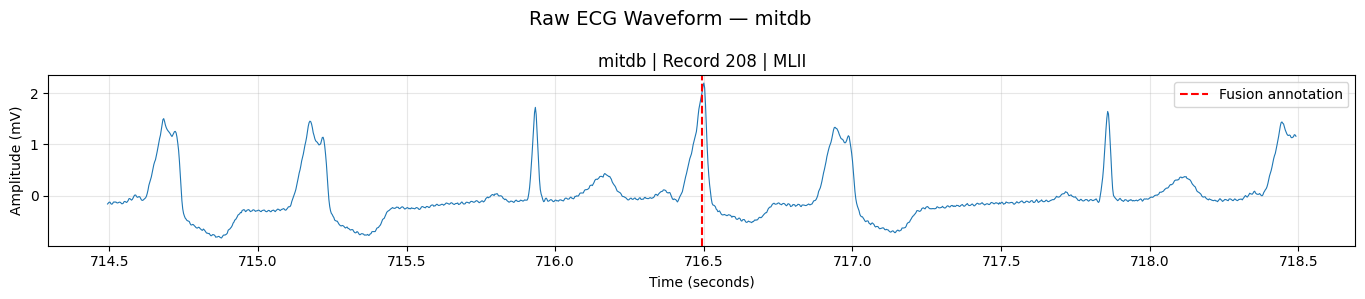

mitdb: Record=208, Sampling=360 Hz, Fusion beats=373, Channels=['MLII', 'V1']


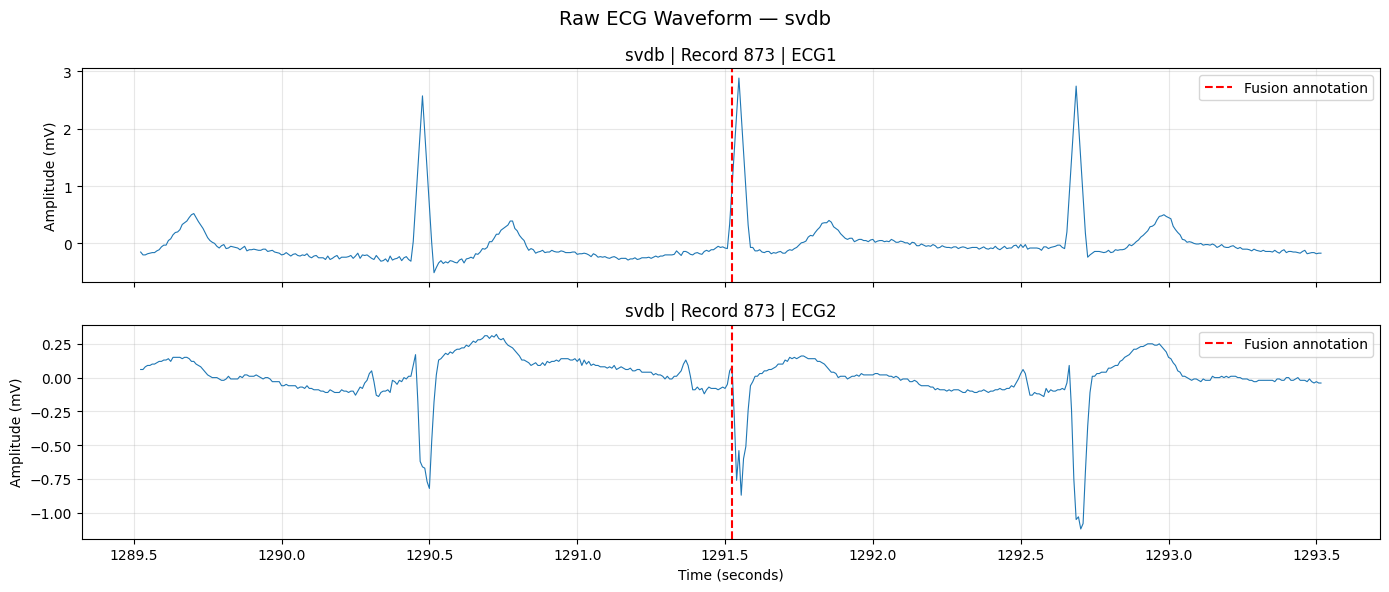

svdb: Record=873, Sampling=128 Hz, Fusion beats=17, Channels=['ECG1', 'ECG2']


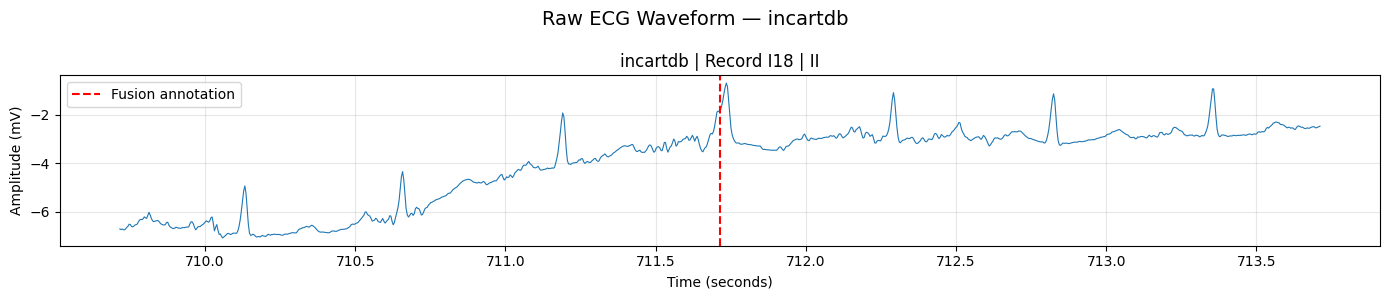

incartdb: Record=I18, Sampling=257 Hz, Fusion beats=56, Channels=['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [ ]:
# This cell plots raw waveform segments of chosen channels containing high numbers of Fusion beats to inspect raw signal quality.
import wfdb
import numpy as np
import matplotlib.pyplot as plt

def get_selected_channels(database, lead_names):
    names = [name.upper() for name in lead_names]
    if database == "mitdb":
        target_leads = ["MLII"]
    elif database == "incartdb":
        target_leads = ["II"]
    elif database == "svdb":
        target_leads = ["ECG1", "ECG2"]
    else:
        return []
    return [i for i, name in enumerate(names) if name in target_leads]

for db in DATABASES:
    candidates = record_df[(record_df["database"] == db) & (record_df["Fusion"] > 0)].sort_values("Fusion", ascending=False)
    if candidates.empty:
        print("No Fusion recordings found:", db)
        continue

    record = str(candidates.iloc[0]["record"])
    record_path = str(RAW_DIR / db / record)
    signal, fields = wfdb.rdsamp(record_path)
    fs = fields["fs"]
    lead_names = fields["sig_name"]
    annotation = wfdb.rdann(record_path, "atr")

    fusion_samples = [int(sample) for sample, symbol in zip(annotation.sample, annotation.symbol) if symbol == "F"]
    if len(fusion_samples) == 0:
        print("No Fusion beats:", db, record)
        continue

    channel_indices = get_selected_channels(db, lead_names)
    if not channel_indices:
        print("Required channel unavailable:", db, record)
        continue

    center = fusion_samples[len(fusion_samples) // 2]
    start = max(0, center - int(2 * fs))
    end = min(len(signal), center + int(2 * fs))
    time_axis = np.arange(start, end) / fs

    fig, axes = plt.subplots(len(channel_indices), 1, figsize=(14, 3 * len(channel_indices)), sharex=True)
    if len(channel_indices) == 1:
        axes = [axes]

    for ax, channel_idx in zip(axes, channel_indices):
        lead_name = lead_names[channel_idx]
        ax.plot(time_axis, signal[start:end, channel_idx], linewidth=0.8)
        ax.axvline(center / fs, color="red", linestyle="--", label="Fusion annotation")
        ax.set_title(f"{db} | Record {record} | {lead_name}")
        ax.set_ylabel(f"Amplitude ({fields["units"][channel_idx]})")
        ax.legend()
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Time (seconds)")
    plt.suptitle(f"Raw ECG Waveform — {db}", fontsize=14)
    plt.tight_layout()
    plt.show()
    print(f"{db}: Record={record}, Sampling={fs} Hz, Fusion beats={len(fusion_samples)}, Channels={lead_names}")


### Step 5.3: Filter and Inspect ECG Signals

Now we will compare raw and filtered ECG signals to understand how preprocessing affects the waveform.

ECG signals may contain baseline wander, high-frequency noise, and other unwanted artifacts. Filtering helps reduce these disturbances while preserving important cardiac features.

#### 5.3.1 Initial Preprocessing Parameters

We will initially use the following preprocessing parameters:

| Parameter | Value |
|---|---|
| Filter | Butterworth Bandpass |
| Filter Order | 4 |
| Lower Cutoff Frequency | 0.5 Hz |
| Upper Cutoff Frequency | 40 Hz |
| Filtering Method | Zero-phase SOS |
| Target Sampling Rate | 256 Hz |

#### 5.3.2 Filtering Method

We will use a **Butterworth bandpass filter** with a frequency range of 0.5–40 Hz.

The filter helps to:

- Reduce baseline wander and low-frequency drift.
- Remove high-frequency noise.
- Preserve important ECG waveform characteristics, including P waves, QRS complexes, and T waves.

We will implement filtering using `sosfiltfilt()` rather than applying `filtfilt()` directly to second-order-section (SOS) coefficients.

**Why SOS filtering?**

Second-order sections provide better numerical stability, particularly when working with digital filters. The forward-backward filtering approach also eliminates phase shifts, preserving the temporal alignment of ECG features.

#### 5.3.3 Inspect Raw vs Filtered Signals

After filtering, we will visualize both signals and compare:

1. Baseline stability.
2. Noise reduction.
3. Preservation of QRS complexes.
4. Overall waveform morphology.

This visual inspection helps us verify that preprocessing improves signal quality without removing clinically relevant information.


/tmp/ipykernel_1425/1107707927.py:152: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()



Database: mitdb
Record: 208
Lead: MLII
Sampling frequency: 360
Units: mV
ADC gain: 200.0
Baseline: 1024
Raw minimum: -3.485
Raw maximum: 3.65


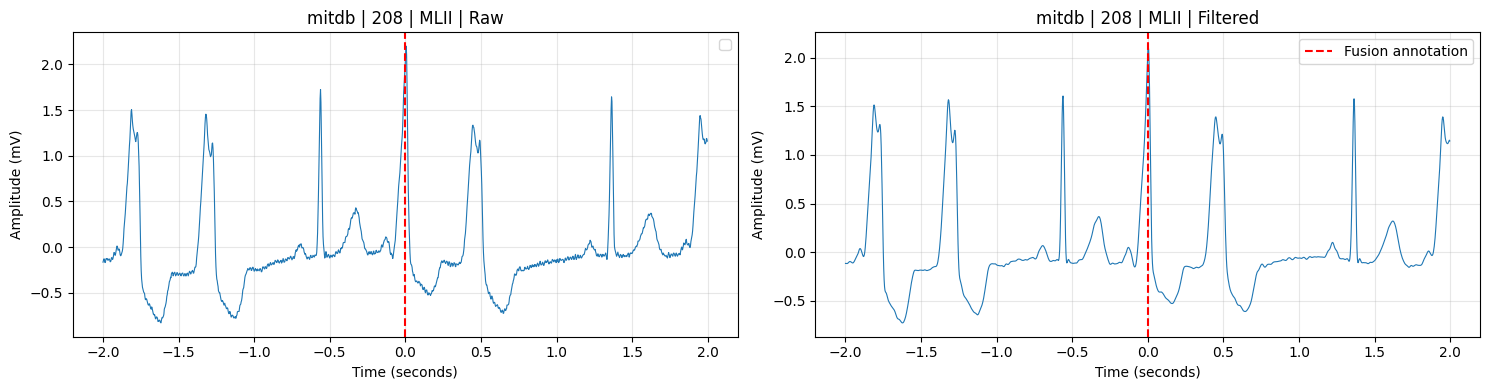

/tmp/ipykernel_1425/1107707927.py:152: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()



Database: svdb
Record: 873
Lead: ECG1
Sampling frequency: 128
Units: mV
ADC gain: 200.0
Baseline: 0
Raw minimum: -1.05
Raw maximum: 4.31


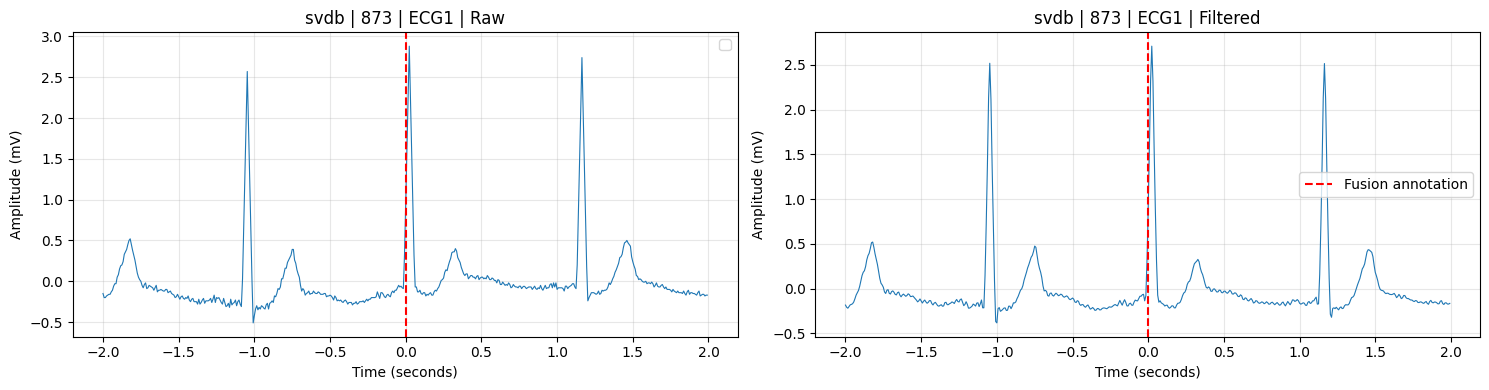

/tmp/ipykernel_1425/1107707927.py:152: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()



Database: incartdb
Record: I18
Lead: II
Sampling frequency: 257
Units: mV
ADC gain: 612.0
Baseline: 0
Raw minimum: -15.089869281045752
Raw maximum: 15.089869281045752


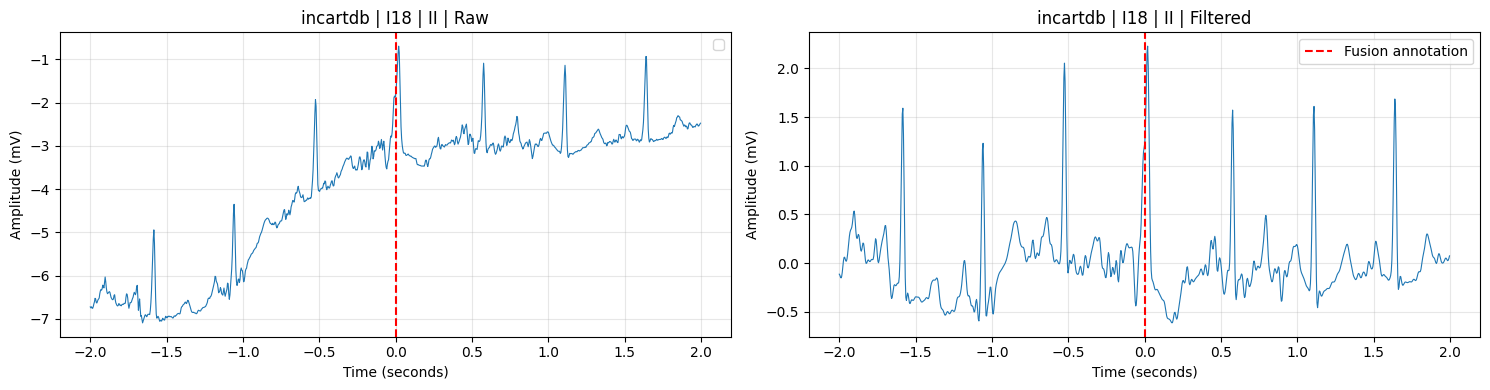

In [ ]:
# This cell configures a Butterworth bandpass filter and compares the original raw waveform with its filtered counterpart.
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

SELECTED_LEADS = {
    "mitdb": ["MLII"],
    "svdb": ["ECG1"],
    "incartdb": ["II"]
}

for db in DATABASES:
    candidates = record_df[(record_df["database"] == db) & (record_df["Fusion"] > 0)].sort_values("Fusion", ascending=False)
    record = str(candidates.iloc[0]["record"])
    record_path = str(RAW_DIR / db / record)
    signal, fields = wfdb.rdsamp(record_path)
    header = wfdb.rdheader(record_path)
    fs = fields["fs"]
    lead_names = fields["sig_name"]
    annotation = wfdb.rdann(record_path, "atr")

    fusion_samples = [int(s) for s, symbol in zip(annotation.sample, annotation.symbol) if symbol == "F"]
    if len(fusion_samples) == 0:
        continue

    center = fusion_samples[len(fusion_samples) // 2]
    channel_indices = [i for i, name in enumerate(lead_names) if name.upper() in SELECTED_LEADS[db]]
    if not channel_indices:
        print("Selected lead missing:", db, record)
        continue

    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    start = max(0, center - int(2 * fs))
    end = min(len(signal), center + int(2 * fs))
    time_axis = (np.arange(start, end) - center) / fs

    fig, axes = plt.subplots(len(channel_indices), 2, figsize=(15, 4 * len(channel_indices)))
    axes = np.atleast_2d(axes)

    for row, channel_idx in enumerate(channel_indices):
        raw_signal = signal[:, channel_idx]
        filtered_signal = sosfiltfilt(sos, raw_signal)
        raw_segment = raw_signal[start:end]
        filtered_segment = filtered_signal[start:end]
        lead = lead_names[channel_idx]

        axes[row, 0].plot(time_axis, raw_segment, linewidth=0.8)
        axes[row, 0].axvline(0, color="red", linestyle="--")
        axes[row, 0].set_title(f"{db} | {record} | {lead} | Raw")

        axes[row, 1].plot(time_axis, filtered_segment, linewidth=0.8)
        axes[row, 1].axvline(0, color="red", linestyle="--", label="Fusion annotation")
        axes[row, 1].set_title(f"{db} | {record} | {lead} | Filtered")

        for ax in axes[row]:
            ax.set_xlabel("Time (seconds)")
            ax.set_ylabel("Amplitude (mV)")
            ax.grid(alpha=0.3)
            ax.legend()

        print("\nDatabase:", db)
        print("Record:", record)
        print("Lead:", lead)
        print("Sampling frequency:", fs)
        print("Units:", fields["units"][channel_idx])
        print("ADC gain:", header.adc_gain[channel_idx])
        print("Baseline:", header.baseline[channel_idx])
        print("Raw minimum:", np.min(raw_signal))
        print("Raw maximum:", np.max(raw_signal))

    plt.tight_layout()
    plt.show()

In [ ]:
# This cell performs a robust signal quality audit across the entire INCART database by examining Lead II metrics.
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

quality_rows = []
incart_records = record_df[record_df["database"] == "incartdb"]["record"].tolist()

for record in incart_records:
    record_path = str(RAW_DIR / "incartdb" / str(record))
    header = wfdb.rdheader(record_path)
    lead_idx = next((i for i, lead in enumerate(header.sig_name) if lead.upper() == "II"), None)
    if lead_idx is None:
        print("Lead II missing:", record)
        continue

    try:
        signal, fields = wfdb.rdsamp(record_path, channels=[lead_idx])
        x = signal[:, 0]
        fs = fields["fs"]

        invalid_count = int(np.sum(~np.isfinite(x)))
        if invalid_count > 0:
            quality_rows.append({
                "record": record,
                "status": "Invalid values",
                "invalid_count": invalid_count
            })
            continue

        sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
        y = sosfiltfilt(sos, x)
        raw_p01, raw_p50, raw_p99 = np.percentile(x, [1, 50, 99])
        filtered_p01, filtered_p50, filtered_p99 = np.percentile(y, [1, 50, 99])
        abs_p999 = np.percentile(np.abs(y - np.median(y)), 99.9)

        differences = np.abs(np.diff(y))
        diff_p99 = np.percentile(differences, 99)

        quality_rows.append({
            "record": record,
            "status": "OK",
            "sampling_frequency": fs,
            "raw_min": np.min(x),
            "raw_max": np.max(x),
            "raw_p01": raw_p01,
            "raw_median": raw_p50,
            "raw_p99": raw_p99,
            "filtered_p01": filtered_p01,
            "filtered_median": filtered_p50,
            "filtered_p99": filtered_p99,
            "filtered_abs_p999": abs_p999,
            "difference_p99": diff_p99,
            "invalid_count": invalid_count
        })
    except Exception as error:
        print("Error:", record, error)

incart_quality_df = pd.DataFrame(quality_rows)
print("INCART SIGNAL QUALITY AUDIT")
display(incart_quality_df.sort_values("filtered_abs_p999", ascending=False).head(15))
incart_quality_df.to_csv(AUDIT_DIR / "incart_signal_quality_audit.csv", index=False)
print("\nSaved INCART quality audit!")

INCART SIGNAL QUALITY AUDIT


,record,status,sampling_frequency,raw_min,raw_max,raw_p01,raw_median,raw_p99,filtered_p01,filtered_median,filtered_p99,filtered_abs_p999,difference_p99,invalid_count
71,I72,OK,257,-7.730009,7.730950,-3.209793,0.668862,3.981185,-3.296658,-0.104954,2.997410,5.821264,0.709502,0
35,I36,OK,257,-17.215686,17.215686,-6.338252,3.748366,11.839886,-1.669733,-0.135313,3.065588,4.998259,0.722997,0
41,I42,OK,257,-9.280389,9.282010,-6.988655,-2.006483,6.457050,-1.391388,-0.147612,3.882805,4.583016,0.597358,0
34,I35,OK,257,-13.916667,13.918301,-8.718954,-1.245098,6.696095,-1.599214,-0.116061,2.845638,4.424626,0.651891,0
43,I44,OK,257,-8.022876,8.022876,-3.694444,1.339869,4.908513,-1.394136,-0.053414,3.409522,4.238368,0.656367,0
50,I51,OK,257,-11.774716,11.776337,-6.786062,4.361426,9.888169,-1.585583,-0.112637,3.336652,4.103938,0.507877,0
45,I46,OK,257,-8.218954,8.220588,-3.228758,2.562092,5.620915,-1.306752,-0.054431,2.603473,4.094154,0.663547,0
44,I45,OK,257,-5.230392,5.230392,-3.155229,-1.132353,2.405229,-1.039443,-0.052892,2.644304,4.011911,0.594090,0
72,I73,OK,257,-7.033866,7.034807,-1.932277,2.200376,3.460960,-3.505958,0.043915,0.958555,3.899853,0.825952,0
36,I37,OK,257,-8.413399,8.415033,-1.062092,3.565359,6.233660,-1.006177,-0.118973,2.367212,3.858689,0.455473,0



Saved INCART quality audit!


In [ ]:
# This cell sets up the dictionary mapping clinical beats to corresponding AAMI-compliant class lists.
CLASS_SYMBOLS = {
    "Normal": ["N", "L", "R", "B", "e", "j"],
    "Supraventricular": ["A", "a", "J", "S", "n"],
    "Ventricular": ["V", "E", "r"],
    "Fusion": ["F"]
}

========== INCART COMPLETE QUALITY SUMMARY ==========
Total recordings: 75
Successfully processed: 75
Invalid or failed recordings: 0


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
filtered_abs_p999,75.0,2.208182,1.173314,0.425131,1.431884,1.944318,2.881476,3.967088,4.294245,5.212240,5.821264
difference_p99,75.0,0.370579,0.160401,0.084711,0.266591,0.346177,0.457266,0.596838,0.658521,0.749765,0.825952
raw_p01,75.0,-4.348028,3.375722,-17.068071,-6.106521,-3.545833,-2.046317,-0.905849,-0.583068,0.013365,0.342742
raw_p99,75.0,4.348290,3.363757,-2.120623,2.053389,3.723343,6.310594,8.834020,10.873371,12.957663,13.782836
filtered_p01,75.0,-0.748463,0.632356,-3.505958,-0.998275,-0.570139,-0.313896,-0.215606,-0.193573,-0.168083,-0.159268
filtered_p99,75.0,1.347161,0.883521,0.223487,0.724041,1.118457,1.709998,2.864551,3.195696,3.595364,3.882805



TOP 10 BY FILTERED AMPLITUDE


,record,filtered_abs_p999,difference_p99,filtered_p01,filtered_p99
71,I72,5.821264,0.709502,-3.296658,2.997410
35,I36,4.998259,0.722997,-1.669733,3.065588
41,I42,4.583016,0.597358,-1.391388,3.882805
34,I35,4.424626,0.651891,-1.599214,2.845638
43,I44,4.238368,0.656367,-1.394136,3.409522
50,I51,4.103938,0.507877,-1.585583,3.336652
45,I46,4.094154,0.663547,-1.306752,2.603473
44,I45,4.011911,0.594090,-1.039443,2.644304
72,I73,3.899853,0.825952,-3.505958,0.958555
36,I37,3.858689,0.455473,-1.006177,2.367212



TOP 10 BY SAMPLE-TO-SAMPLE CHANGE


,record,filtered_abs_p999,difference_p99
72,I73,3.899853,0.825952
35,I36,4.998259,0.722997
71,I72,5.821264,0.709502
45,I46,4.094154,0.663547
43,I44,4.238368,0.656367
34,I35,4.424626,0.651891
21,I22,2.915667,0.617609
41,I42,4.583016,0.597358
19,I20,2.375458,0.596057
44,I45,4.011911,0.594090


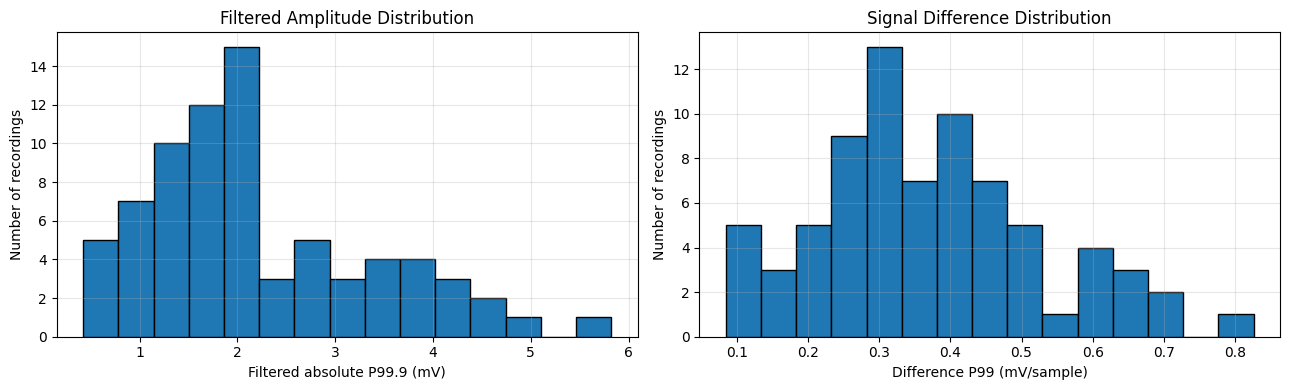


Complete quality summary saved!


In [ ]:
# This cell filters out invalid INCART recordings and constructs data distribution charts for quality parameters.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

valid_df = incart_quality_df[incart_quality_df["status"] == "OK"].copy()
print("========== INCART COMPLETE QUALITY SUMMARY ==========")
print("Total recordings:", len(incart_quality_df))
print("Successfully processed:", len(valid_df))
print("Invalid or failed recordings:", len(incart_quality_df) - len(valid_df))

metrics = ["filtered_abs_p999", "difference_p99", "raw_p01", "raw_p99", "filtered_p01", "filtered_p99"]
display(valid_df[metrics].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T)

print("\nTOP 10 BY FILTERED AMPLITUDE")
display(valid_df.nlargest(10, "filtered_abs_p999")[["record", "filtered_abs_p999", "difference_p99", "filtered_p01", "filtered_p99"]])

print("\nTOP 10 BY SAMPLE-TO-SAMPLE CHANGE")
display(valid_df.nlargest(10, "difference_p99")[["record", "filtered_abs_p999", "difference_p99"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(valid_df["filtered_abs_p999"], bins=15, edgecolor="black")
axes[0].set_title("Filtered Amplitude Distribution")
axes[0].set_xlabel("Filtered absolute P99.9 (mV)")
axes[0].set_ylabel("Number of recordings")
axes[0].grid(alpha=0.3)

axes[1].hist(valid_df["difference_p99"], bins=15, edgecolor="black")
axes[1].set_title("Signal Difference Distribution")
axes[1].set_xlabel("Difference P99 (mV/sample)")
axes[1].set_ylabel("Number of recordings")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

valid_df.to_csv(AUDIT_DIR / "incart_quality_summary_complete.csv", index=False)
print("\nComplete quality summary saved!")

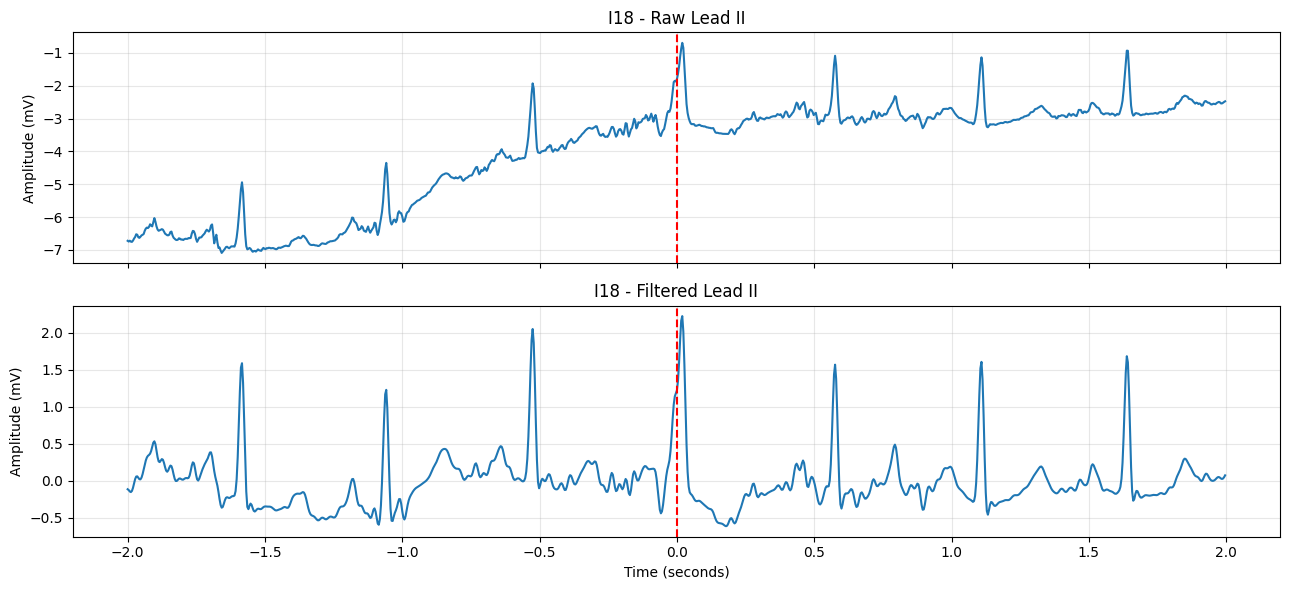

No Fusion annotations: I72


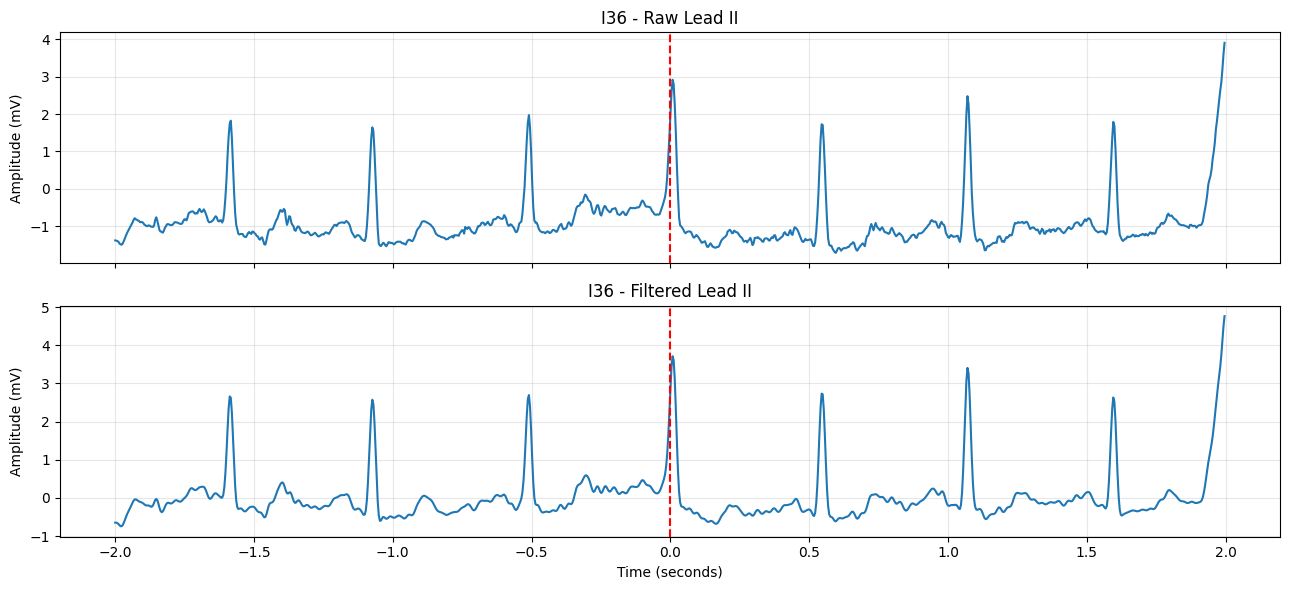

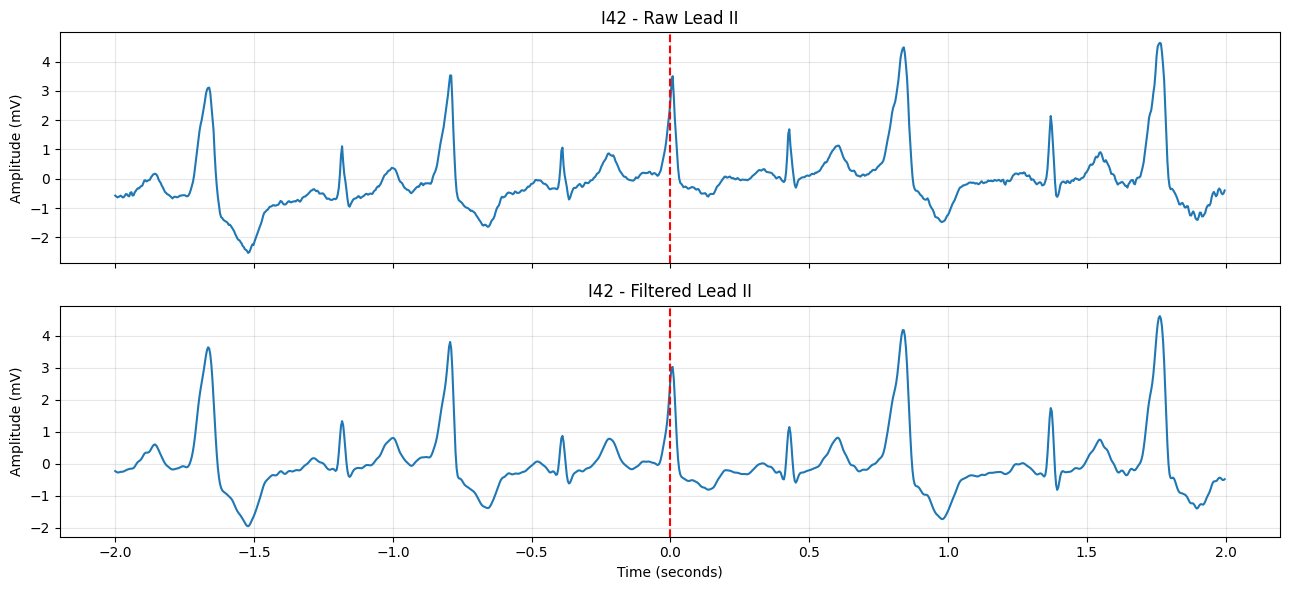

In [ ]:
# This cell compares raw and filtered Lead II signals for specific candidate recordings of interest (I18, I72, I36, I42).
import wfdb
import numpy as np
import matplotlib.pyplot as plt

inspect_records = ["I18", "I72", "I36", "I42"]
for record in inspect_records:
    record_path = str(RAW_DIR / "incartdb" / record)
    signal, fields = wfdb.rdsamp(record_path)
    lead_idx = [i for i, name in enumerate(fields["sig_name"]) if name.upper() == "II"][0]

    x = signal[:, lead_idx]
    fs = fields["fs"]
    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)
    ann = wfdb.rdann(record_path, "atr")
    fusion = [s for s, symbol in zip(ann.sample, ann.symbol) if symbol == "F"]

    if not fusion:
        print("No Fusion annotations:", record)
        continue

    center = fusion[len(fusion)//2]
    start = max(0, center - 2*fs)
    end = min(len(x), center + 2*fs)
    t = (np.arange(start, end) - center) / fs

    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    axes[0].plot(t, x[start:end])
    axes[0].axvline(0, color="red", linestyle="--")
    axes[0].set_title(f"{record} - Raw Lead II")

    axes[1].plot(t, y[start:end])
    axes[1].axvline(0, color="red", linestyle="--")
    axes[1].set_title(f"{record} - Filtered Lead II")

    for ax in axes:
        ax.set_ylabel("Amplitude (mV)")
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("Time (seconds)")
    plt.tight_layout()
    plt.show()


========== I18 ==========
Sampling frequency: 257
Total annotations: 3084
Fusion annotations: 56
Recognized beat annotations: 3084


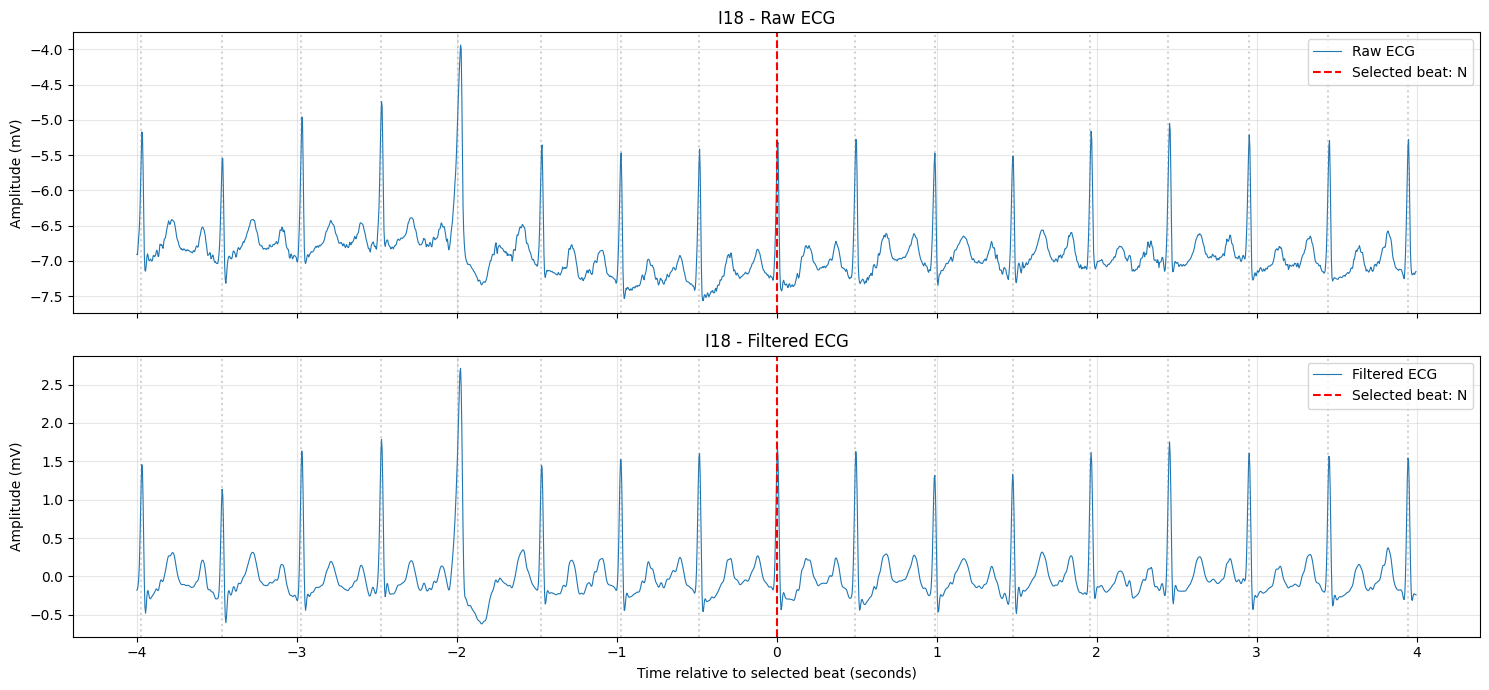

Selected annotation: N
Selected sample: 225980

========== I72 ==========
Sampling frequency: 257
Total annotations: 2270
Fusion annotations: 0
Recognized beat annotations: 2270


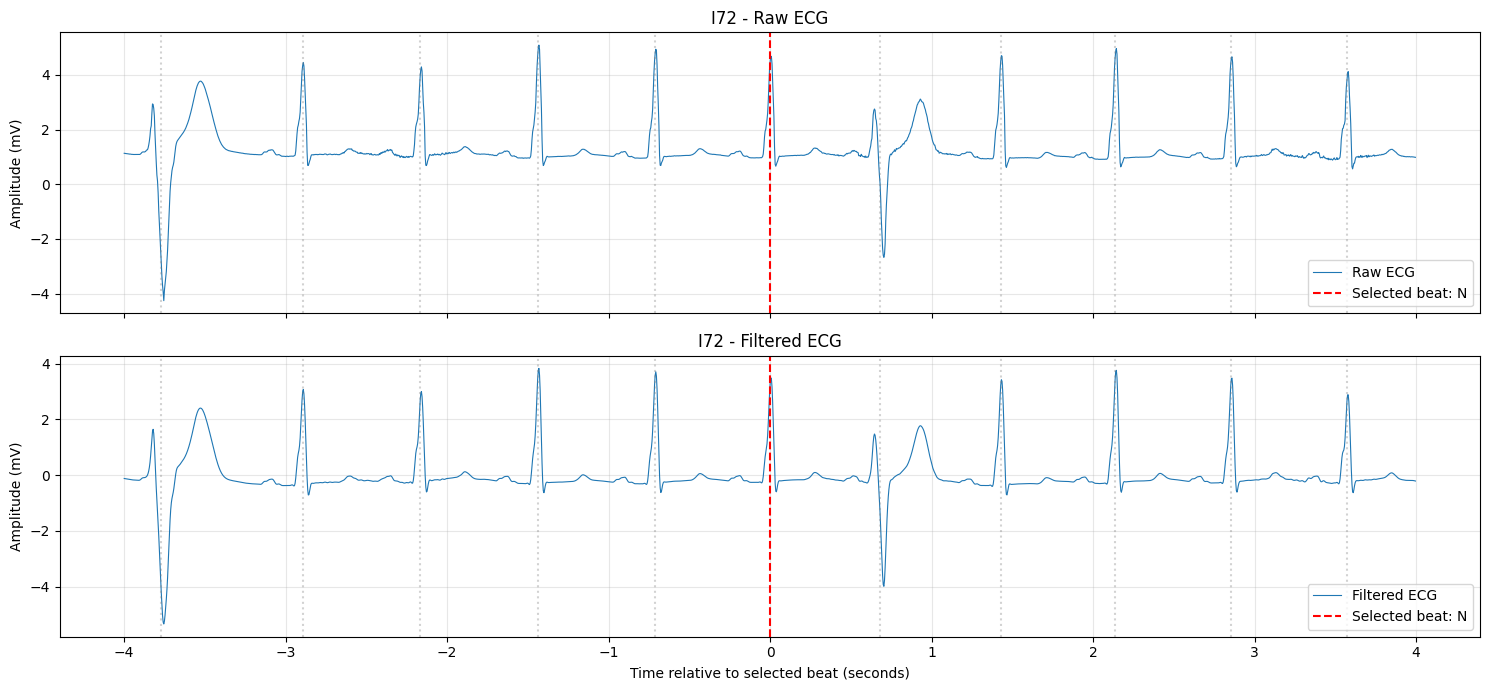

Selected annotation: N
Selected sample: 224839

========== I36 ==========
Sampling frequency: 257
Total annotations: 3911
Fusion annotations: 12
Recognized beat annotations: 3911


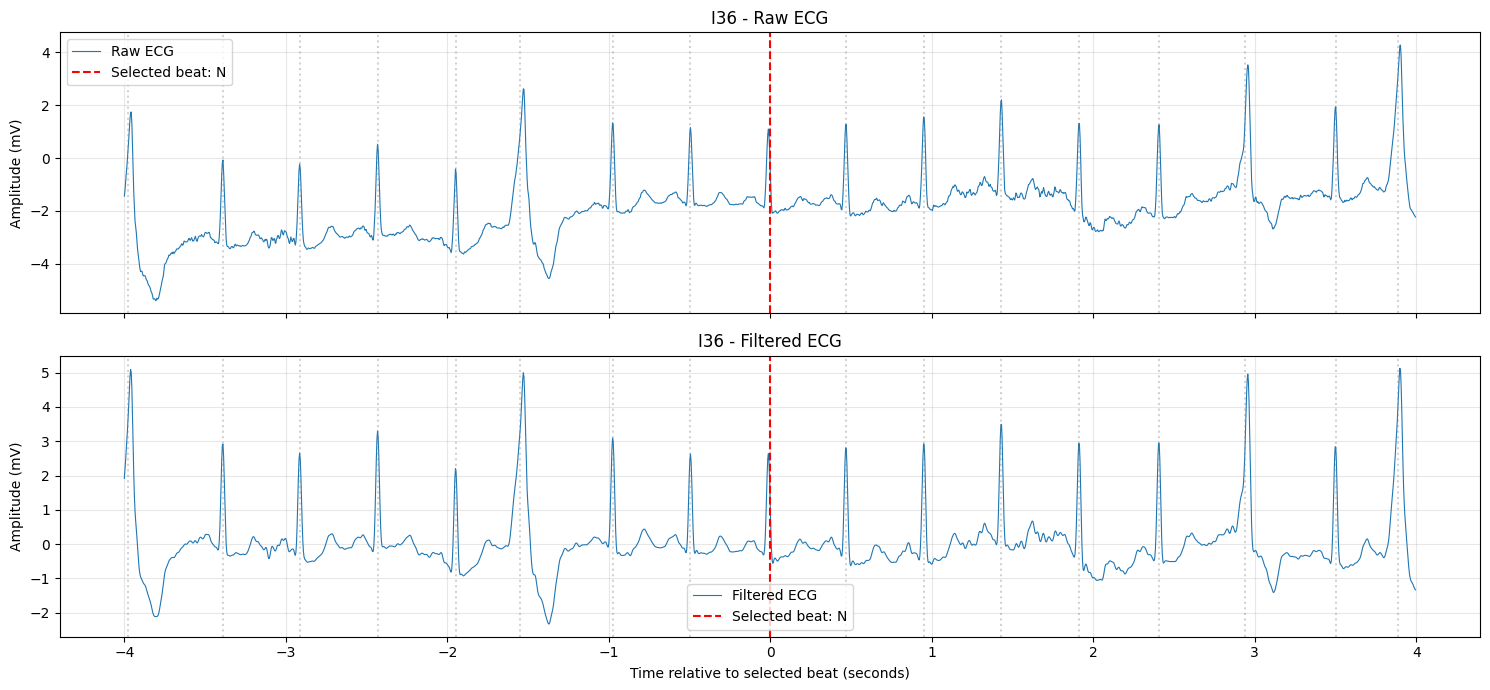

Selected annotation: N
Selected sample: 198353

========== I42 ==========
Sampling frequency: 257
Total annotations: 3109
Fusion annotations: 9
Recognized beat annotations: 3109


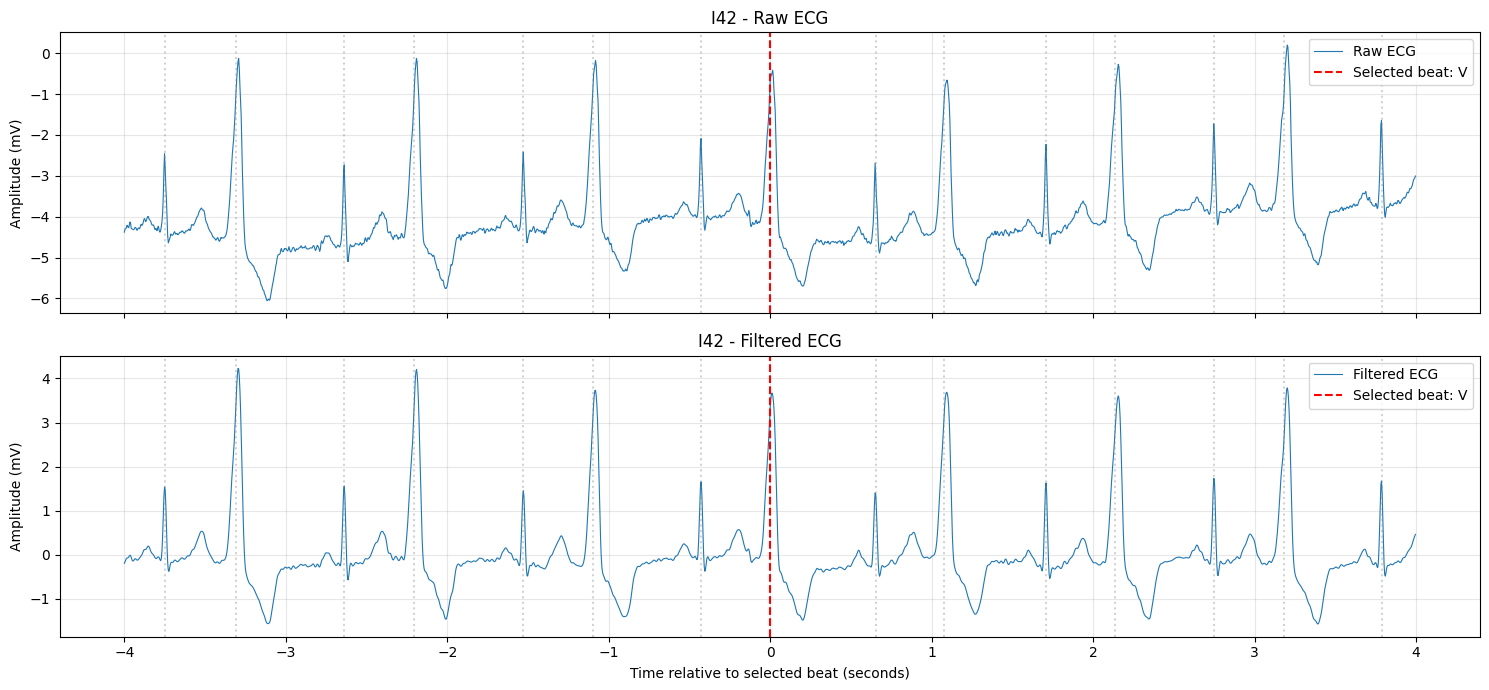

Selected annotation: V
Selected sample: 237512


In [ ]:
# This cell plots detailed comparison segments containing beat marker ticks to show exactly where individual classifications fall.
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

inspect_records = ["I18", "I72", "I36", "I42"]
BEAT_SYMBOLS = {
    "N", "L", "R", "B", "A", "a", "J", "S", "V", "r", "F", "e", "j", "E", "/", "f", "Q", "?"
}

for record in inspect_records:
    record_path = str(RAW_DIR / "incartdb" / record)
    header = wfdb.rdheader(record_path)
    lead_idx = next((i for i, name in enumerate(header.sig_name) if name.upper() == "II"), None)
    if lead_idx is None:
        print("Lead II unavailable:", record)
        continue

    signal, fields = wfdb.rdsamp(record_path, channels=[lead_idx])
    x = signal[:, 0]
    fs = fields["fs"]
    ann = wfdb.rdann(record_path, "atr")
    beats = [(int(sample), symbol) for sample, symbol in zip(ann.sample, ann.symbol) if symbol in BEAT_SYMBOLS]

    print("\n==========", record, "==========")
    print("Sampling frequency:", fs)
    print("Total annotations:", len(ann.sample))
    print("Fusion annotations:", sum(s == "F" for s in ann.symbol))
    print("Recognized beat annotations:", len(beats))

    if not beats:
        print("No recognized beat annotations.")
        continue

    center, center_symbol = beats[len(beats)//2]
    start = max(0, center - int(4 * fs))
    end = min(len(x), center + int(4 * fs))

    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)
    t = (np.arange(start, end) - center) / fs

    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    for ax, data, title in zip(axes, [x, y], ["Raw ECG", "Filtered ECG"]):
        ax.plot(t, data[start:end], linewidth=0.8, label=title)
        for sample, symbol in beats:
            if start <= sample < end:
                position = (sample - center) / fs
                if sample == center:
                    ax.axvline(position, color="red", linestyle="--", label=f"Selected beat: {center_symbol}")
                else:
                    ax.axvline(position, color="gray", alpha=0.35, linestyle=":")
        ax.set_title(f"{record} - {title}")
        ax.set_ylabel("Amplitude (mV)")
        ax.grid(alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Time relative to selected beat (seconds)")
    plt.tight_layout()
    plt.show()
    print("Selected annotation:", center_symbol)
    print("Selected sample:", center)

Write the next code cell
Create a new section in your notebook:

Phase 6.1 — Complete Annotation Audit Across All Databases

In [ ]:
# This cell generates a complete annotation audit across MITDB, SVDB, and INCARTDB to summarize individual symbol statistics.
import wfdb
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter

DATABASES = ["mitdb", "svdb", "incartdb"]
BEAT_SYMBOLS = {
    "N", "L", "R", "B", "A", "a", "J", "S", "V", "r", "E", "F", "e", "j", "n", "/", "f", "Q", "?"
}

record_rows = []
symbol_rows = []
failed_records = []

for database in DATABASES:
    db_path = Path(RAW_DIR) / database
    hea_files = sorted(db_path.glob("*.hea"))
    print("\n" + "=" * 55)
    print("DATABASE:", database)
    print("Available recordings:", len(hea_files))
    print("=" * 55)

    for hea_file in hea_files:
        record = hea_file.stem
        record_path = str(hea_file.with_suffix(""))
        try:
            ann = wfdb.rdann(record_path, "atr")
            counts = Counter(ann.symbol)
            total_annotations = len(ann.symbol)
            recognized_beats = sum(count for symbol, count in counts.items() if symbol in BEAT_SYMBOLS)
            fusion_count = counts.get("F", 0)

            record_rows.append({
                "database": database,
                "record": record,
                "total_annotations": total_annotations,
                "recognized_beats": recognized_beats,
                "fusion_count": fusion_count,
                "other_annotations": total_annotations - recognized_beats
            })
            for symbol, count in counts.items():
                symbol_rows.append({
                    "database": database,
                    "record": record,
                    "symbol": symbol,
                    "count": count
                })
        except Exception as e:
            failed_records.append({
                "database": database,
                "record": record,
                "error": str(e)
            })
    print("Completed:", database)

record_audit_df = pd.DataFrame(record_rows)
symbol_audit_df = pd.DataFrame(symbol_rows)
failed_audit_df = pd.DataFrame(failed_records)

database_summary = record_audit_df.groupby("database").agg(
    recordings=("record", "nunique"),
    total_annotations=("total_annotations", "sum"),
    recognized_beats=("recognized_beats", "sum"),
    fusion_beats=("fusion_count", "sum"),
    records_with_fusion=("fusion_count", lambda x: (x > 0).sum())
).reset_index()

print("\n========== DATABASE SUMMARY ==========")
display(database_summary)

symbol_summary = symbol_audit_df.groupby(["database", "symbol"])["count"].sum().reset_index().sort_values(["database", "count"], ascending=[True, False])
print("\n========== SYMBOL DISTRIBUTION ==========")
display(symbol_summary)

fusion_records = record_audit_df[record_audit_df["fusion_count"] > 0].sort_values("fusion_count", ascending=False)
print("\n========== FUSION RECORDS ==========")
display(fusion_records)

unrecognized_symbols = symbol_summary[~symbol_summary["symbol"].isin(BEAT_SYMBOLS)]
print("\n========== OTHER ANNOTATION SYMBOLS ==========")
display(unrecognized_symbols)

print("\n========== FAILED RECORDINGS ==========")
display(failed_audit_df)

database_summary.to_csv("database_summary_v2.csv", index=False)
record_audit_df.to_csv("record_annotation_audit_v2.csv", index=False)
symbol_summary.to_csv("annotation_symbol_audit_v2.csv", index=False)
fusion_records.to_csv("fusion_records_v2.csv", index=False)
print("\nAll annotation audit reports saved!")


DATABASE: mitdb
Available recordings: 48
Completed: mitdb

DATABASE: svdb
Available recordings: 78
Completed: svdb

DATABASE: incartdb
Available recordings: 75
Completed: incartdb

========== DATABASE SUMMARY ==========


,database,recordings,total_annotations,recognized_beats,fusion_beats,records_with_fusion
0,incartdb,75,175919,175907,219,22
1,mitdb,48,112647,109494,803,17
2,svdb,78,187877,184583,23,6



========== SYMBOL DISTRIBUTION ==========


,database,symbol,count
4,incartdb,N,150410
8,incartdb,V,20013
6,incartdb,R,3174
1,incartdb,A,1944
3,incartdb,F,219
9,incartdb,j,92
10,incartdb,n,32
7,incartdb,S,16
0,incartdb,+,12
5,incartdb,Q,6



========== FUSION RECORDS ==========


,database,record,total_annotations,recognized_beats,fusion_count,other_annotations
29,mitdb,208,3040,2955,373,85
33,mitdb,213,3294,3251,362,43
143,incartdb,I18,3084,3084,56,0
199,incartdb,I74,2405,2405,48,0
160,incartdb,I35,3676,3676,18,0
104,svdb,873,1684,1684,17,0
129,incartdb,I04,2424,2424,17,0
41,mitdb,223,2643,2605,14,38
161,incartdb,I36,3911,3911,12,0
187,incartdb,I62,2269,2269,12,0



========== OTHER ANNOTATION SYMBOLS ==========


,database,symbol,count
0,incartdb,+,12
13,mitdb,+,1291
33,mitdb,~,616
11,mitdb,!,472
12,mitdb,"""",437
31,mitdb,x,193
32,mitdb,|,132
25,mitdb,[,6
26,mitdb,],6
43,svdb,|,2211



========== FAILED RECORDINGS ==========


""



All annotation audit reports saved!


In [ ]:
# This cell performs direct verification on recording I18 to validate overall annotation audits and trace fusion peak indexes.
from collections import Counter
from pathlib import Path
import wfdb

record_path = str(Path(RAW_DIR) / "incartdb" / "I18")
ann_check = wfdb.rdann(record_path, "atr")
symbol_counts = Counter(ann_check.symbol)

print("========== I18 DIRECT VERIFICATION ==========")
print("Total annotations:", len(ann_check.symbol))
print("Fusion annotations:", symbol_counts.get("F", 0))
print("All annotation symbols:")
print(symbol_counts)

fusion_samples = [int(sample) for sample, symbol in zip(ann_check.sample, ann_check.symbol) if symbol == "F"]
print("\nFirst 15 Fusion sample positions:")
print(fusion_samples[:15])

print("\n========== PREVIOUS AUDIT ==========")
display(symbol_audit_df[(symbol_audit_df["database"] == "incartdb") & (symbol_audit_df["record"] == "I18")])
display(record_audit_df[(record_audit_df["database"] == "incartdb") & (record_audit_df["record"] == "I18")])

========== I18 DIRECT VERIFICATION ==========
Total annotations: 3084
Fusion annotations: 56
All annotation symbols:
Counter({'N': 2662, 'V': 366, 'F': 56})

First 15 Fusion sample positions:
[25879, 32120, 33575, 42410, 50399, 54647, 66481, 78355, 79082, 100908, 106303, 112364, 115720, 118242, 118922]

========== PREVIOUS AUDIT ==========


,database,record,symbol,count
666,incartdb,I18,N,2662
667,incartdb,I18,V,366
668,incartdb,I18,F,56


,database,record,total_annotations,recognized_beats,fusion_count,other_annotations
143,incartdb,I18,3084,3084,56,0


In [ ]:
# This cell extracts patient group comments and mappings from database headers to build a clean registry.
import wfdb
import pandas as pd
import re
from pathlib import Path

DATABASES = ["mitdb", "svdb", "incartdb"]
patient_rows = []

for database in DATABASES:
    db_path = Path(RAW_DIR) / database
    hea_files = sorted(db_path.glob("*.hea"))

    for hea_file in hea_files:
        record = hea_file.stem
        record_path = str(hea_file.with_suffix(""))
        header = wfdb.rdheader(record_path)
        comments = getattr(header, "comments", []) or []
        comment_text = " | ".join(comments)

        patient_id = None
        group_id = None
        grouping_status = None

        if database == "incartdb":
            patterns = [
                r"patient\s*(?:number|no\.?|id)?\s*[:=#-]?\s*(\d+)",
                r"\bpt\s*[:=#-]\s*(\d+)"
            ]
            for pattern in patterns:
                match = re.search(pattern, comment_text, flags=re.IGNORECASE)
                if match:
                    patient_id = int(match.group(1))
                    break
            if patient_id is not None:
                group_id = f"incart_patient_{patient_id:02d}"
                grouping_status = "PATIENT_IDENTIFIED"
            else:
                grouping_status = "PATIENT_ID_NOT_PARSED"
        elif database == "mitdb":
            if record in ["201", "202"]:
                group_id = "mitdb_subject_201_202"
            else:
                group_id = f"mitdb_subject_{record}"
            patient_id = group_id
            grouping_status = "PATIENT_GROUP_IDENTIFIED"
        elif database == "svdb":
            patient_id = None
            group_id = f"svdb_record_{record}"
            grouping_status = "RECORD_ONLY_PATIENT_UNKNOWN"

        patient_rows.append({
            "database": database,
            "record": record,
            "patient_id": patient_id,
            "group_id": group_id,
            "grouping_status": grouping_status,
            "sampling_frequency": header.fs,
            "comments": comment_text
        })

patient_registry = pd.DataFrame(patient_rows)
print("========== PATIENT REGISTRY ==========")
display(patient_registry.head(20))

incart_registry = patient_registry[patient_registry["database"] == "incartdb"]
print("\n========== INCART PATIENT SUMMARY ==========")
print("Total recordings:", len(incart_registry))
print("Identified patient IDs:", incart_registry["patient_id"].nunique())

incart_patient_summary = incart_registry.groupby("patient_id").agg(
    recording_count=("record", "count"),
    records=("record", lambda x: ", ".join(x))
).reset_index()
display(incart_patient_summary)

patient_registry.to_csv("ecg_guard_patient_registry_v2.csv", index=False)
incart_patient_summary.to_csv("incart_patient_group_summary.csv", index=False)
print("\nPatient registry saved successfully!")

========== PATIENT REGISTRY ==========


,database,record,patient_id,group_id,grouping_status,sampling_frequency,comments
0,mitdb,100,mitdb_subject_100,mitdb_subject_100,PATIENT_GROUP_IDENTIFIED,360,"69 M 1085 1629 x1 | Aldomet, Inderal"
1,mitdb,101,mitdb_subject_101,mitdb_subject_101,PATIENT_GROUP_IDENTIFIED,360,75 F 1011 654 x1 | Diapres
2,mitdb,102,mitdb_subject_102,mitdb_subject_102,PATIENT_GROUP_IDENTIFIED,360,84 F 1525 167 x1 | Digoxin | The rhythm is pac...
3,mitdb,103,mitdb_subject_103,mitdb_subject_103,PATIENT_GROUP_IDENTIFIED,360,"-1 M 742 654 x1 | Diapres, Xyloprim"
4,mitdb,104,mitdb_subject_104,mitdb_subject_104,PATIENT_GROUP_IDENTIFIED,360,"66 F 1567 694 x1 | Digoxin, Pronestyl | The ra..."
5,mitdb,105,mitdb_subject_105,mitdb_subject_105,PATIENT_GROUP_IDENTIFIED,360,"73 F 1624 1629 x1 | Digoxin, Nitropaste, Prone..."
6,mitdb,106,mitdb_subject_106,mitdb_subject_106,PATIENT_GROUP_IDENTIFIED,360,24 F 1581 654 x1 | Inderal | The PVCs are mult...
7,mitdb,107,mitdb_subject_107,mitdb_subject_107,PATIENT_GROUP_IDENTIFIED,360,63 M 1340 167 x1 | Digoxin | Complete heart bl...
8,mitdb,108,mitdb_subject_108,mitdb_subject_108,PATIENT_GROUP_IDENTIFIED,360,"87 F 1227 654 x1 | Digoxin, Quinaglute | There..."
9,mitdb,109,mitdb_subject_109,mitdb_subject_109,PATIENT_GROUP_IDENTIFIED,360,64 M 1508 694 x1 | Quinidine | There is first ...



========== INCART PATIENT SUMMARY ==========
Total recordings: 75
Identified patient IDs: 32
Missing patient IDs: 0


,patient_id,recording_count,records
0,1,2,"I01, I02"
1,2,3,"I03, I04, I05"
2,3,2,"I06, I07"
3,4,1,I08
4,5,3,"I09, I10, I11"
5,6,3,"I12, I13, I14"
6,7,1,I15
7,8,2,"I16, I17"
8,9,2,"I18, I19"
9,10,3,"I20, I21, I22"



========== MIT-BIH GROUP SUMMARY ==========
Total recordings: 48
Unique subject groups: 47


,database,record,patient_id,group_id,grouping_status,sampling_frequency,comments
24,mitdb,201,mitdb_subject_201_202,mitdb_subject_201_202,PATIENT_GROUP_IDENTIFIED,360,"68 M 1960 2851 x1 | Digoxin, Hydrochlorthiazid..."
25,mitdb,202,mitdb_subject_201_202,mitdb_subject_201_202,PATIENT_GROUP_IDENTIFIED,360,"68 M 1960 2851 x1 | Digoxin, Hydrochlorthiazid..."



========== SVDB HEADER INSPECTION ==========
Total recordings: 78
Records with comments: 0


,record,comments,grouping_status
48,800,,RECORD_ONLY_PATIENT_UNKNOWN
49,801,,RECORD_ONLY_PATIENT_UNKNOWN
50,802,,RECORD_ONLY_PATIENT_UNKNOWN
51,803,,RECORD_ONLY_PATIENT_UNKNOWN
52,804,,RECORD_ONLY_PATIENT_UNKNOWN
53,805,,RECORD_ONLY_PATIENT_UNKNOWN
54,806,,RECORD_ONLY_PATIENT_UNKNOWN
55,807,,RECORD_ONLY_PATIENT_UNKNOWN
56,808,,RECORD_ONLY_PATIENT_UNKNOWN
57,809,,RECORD_ONLY_PATIENT_UNKNOWN



Patient registry saved successfully!


In [ ]:
# This cell categorizes every annotated beat into the four primary AAMI categories and saves patient group summaries.
import wfdb
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter

SYMBOL_TO_CLASS = {
    "N": "Normal", "L": "Normal", "R": "Normal", "B": "Normal", "e": "Normal", "j": "Normal",
    "A": "Supraventricular", "a": "Supraventricular", "J": "Supraventricular", "S": "Supraventricular", "n": "Supraventricular",
    "V": "Ventricular", "E": "Ventricular", "r": "Ventricular",
    "F": "Fusion"
}
CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]
Q_SYMBOLS = {"/", "f", "Q"}

record_class_rows = []
failed_records = []

for _, row in patient_registry.iterrows():
    database = row["database"]
    record = str(row["record"])
    record_path = Path(RAW_DIR) / database / record
    try:
        ann = wfdb.rdann(str(record_path), "atr")
        symbol_counts = Counter(ann.symbol)
        class_counts = {class_name: 0 for class_name in CLASS_NAMES}

        for symbol, count in symbol_counts.items():
            class_name = SYMBOL_TO_CLASS.get(symbol)
            if class_name is not None:
                class_counts[class_name] += count

        total_four_class_beats = sum(class_counts.values())
        q_count = sum(symbol_counts.get(symbol, 0) for symbol in Q_SYMBOLS)
        other_count = len(ann.symbol) - total_four_class_beats - q_count

        record_class_rows.append({
            "database": database,
            "record": record,
            "group_id": row["group_id"] if database in ["mitdb", "incartdb"] else None,
            "total_annotations": len(ann.symbol),
            **class_counts,
            "four_class_beats": total_four_class_beats,
            "excluded_Q": q_count,
            "other_annotations": other_count
        })
    except Exception as e:
        failed_records.append({"database": database, "record": record, "error": str(e)})

record_class_df = pd.DataFrame(record_class_rows)
print("========== RECORD CLASS AUDIT ==========")
display(record_class_df.head(10))

database_summary = record_class_df.groupby("database").agg(
    recordings=("record", "count"),
    Normal=("Normal", "sum"),
    Supraventricular=("Supraventricular", "sum"),
    Ventricular=("Ventricular", "sum"),
    Fusion=("Fusion", "sum"),
    four_class_beats=("four_class_beats", "sum"),
    excluded_Q=("excluded_Q", "sum")
).reset_index()

print("\n========== DATABASE CLASS SUMMARY ==========")
display(database_summary)

known_patient_records = record_class_df[record_class_df["database"].isin(["mitdb", "incartdb"])].copy()
patient_class_df = known_patient_records.groupby(["database", "group_id"], as_index=False).agg(
    recording_count=("record", "count"),
    records=("record", lambda x: ", ".join(x)),
    Normal=("Normal", "sum"),
    Supraventricular=("Supraventricular", "sum"),
    Ventricular=("Ventricular", "sum"),
    Fusion=("Fusion", "sum")
)

print("\n========== PATIENT-LEVEL CLASS SUMMARY ==========")
display(patient_class_df)

record_class_df.to_csv("ecg_guard_record_class_audit.csv", index=False)
database_summary.to_csv("ecg_guard_database_class_summary.csv", index=False)
patient_class_df.to_csv("ecg_guard_patient_class_summary.csv", index=False)
print("\nAll patient-level class audits saved successfully!")

========== RECORD CLASS AUDIT ==========
Successfully processed: 201
Failed records: 0


,database,record,group_id,total_annotations,Normal,Supraventricular,Ventricular,Fusion,four_class_beats,excluded_Q,other_annotations
0,mitdb,100,mitdb_subject_100,2274,2239,33,1,0,2273,0,1
1,mitdb,101,mitdb_subject_101,1874,1860,3,0,0,1863,2,9
2,mitdb,102,mitdb_subject_102,2192,99,0,4,0,103,2084,5
3,mitdb,103,mitdb_subject_103,2091,2082,2,0,0,2084,0,7
4,mitdb,104,mitdb_subject_104,2311,163,0,2,0,165,2064,82
5,mitdb,105,mitdb_subject_105,2691,2526,0,41,0,2567,5,119
6,mitdb,106,mitdb_subject_106,2098,1507,0,520,0,2027,0,71
7,mitdb,107,mitdb_subject_107,2140,0,0,59,0,59,2078,3
8,mitdb,108,mitdb_subject_108,1824,1740,4,17,2,1763,0,61
9,mitdb,109,mitdb_subject_109,2535,2492,0,38,2,2532,0,3



========== DATABASE CLASS SUMMARY ==========


,database,recordings,Normal,Supraventricular,Ventricular,Fusion,four_class_beats,excluded_Q
0,incartdb,75,153677,1992,20013,219,175901,6
1,mitdb,48,90631,2781,7236,803,101451,8043
2,svdb,78,162340,12198,9943,23,184504,79



========== PATIENT-LEVEL CLASS SUMMARY ==========


,database,group_id,recording_count,records,Normal,Supraventricular,Ventricular,Fusion
0,incartdb,incart_patient_01,2,"I01, I02",4858,0,573,0
1,incartdb,incart_patient_02,3,"I03, I04, I05",6115,18,493,26
2,incartdb,incart_patient_03,2,"I06, I07",5076,113,10,0
3,incartdb,incart_patient_04,1,I08,1777,2,351,0
4,incartdb,incart_patient_05,3,"I09, I10, I11",8625,32,128,0
...,...,...,...,...,...,...,...,...
74,mitdb,mitdb_subject_230,1,230,2255,0,1,0
75,mitdb,mitdb_subject_231,1,231,1568,1,2,0
76,mitdb,mitdb_subject_232,1,232,398,1382,0,0
77,mitdb,mitdb_subject_233,1,233,2230,7,831,11


... (3 outputs left out)

,database,group_id,recording_count,records,Normal,Supraventricular,Ventricular,Fusion
60,mitdb,mitdb_subject_208,1,208,1586,2,992,373
64,mitdb,mitdb_subject_213,1,213,2641,28,220,362
8,incartdb,incart_patient_09,2,"I18, I19",3875,0,1216,56
31,incartdb,incart_patient_32,2,"I74, I75",3566,0,887,55
15,incartdb,incart_patient_16,3,"I35, I36, I37",8658,0,1360,30
1,incartdb,incart_patient_02,3,"I03, I04, I05",6115,18,493,26
26,incartdb,incart_patient_27,3,"I62, I63, I64",5187,10,956,23
72,mitdb,mitdb_subject_223,1,223,2045,73,473,14
58,mitdb,mitdb_subject_205,1,205,2571,3,71,11
77,mitdb,mitdb_subject_233,1,233,2230,7,831,11



========== SVDB CLASS SUPPORT ==========
Normal | Beats: 162340 | Records: 78
Supraventricular | Beats: 12198 | Records: 73
Ventricular | Beats: 9943 | Records: 67
Fusion | Beats: 23 | Records: 6

SVDB Fusion-containing records:


,record,Normal,Supraventricular,Ventricular,Fusion
48,800,1846,30,6,1
51,803,1924,0,143,1
54,806,2952,40,29,2
59,811,1406,1,28,1
104,873,1626,15,26,17
106,875,1946,8,97,1



All patient-level class audits saved successfully!


In [ ]:
# This cell prepares datasets for patient-independent stratification by pulling out patient group information.
import numpy as np
import pandas as pd

CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]
DATABASES = ["mitdb", "incartdb"]

group_df = patient_class_df[patient_class_df["database"].isin(DATABASES)].copy()
assert not group_df.duplicated(["database", "group_id"]).any()

print("========== DATASET PREPARATION ==========")
print("Total patient groups:", len(group_df))
display(group_df.groupby("database").agg(
    patients=("group_id", "nunique"),
    recordings=("recording_count", "sum"),
    Normal=("Normal", "sum"),
    Supraventricular=("Supraventricular", "sum"),
    Ventricular=("Ventricular", "sum"),
    Fusion=("Fusion", "sum")
))
print("\nPatient dataset prepared successfully!")

========== DATASET PREPARATION ==========
Total patient groups: 79

Database distribution:


,patients,recordings,Normal,Supraventricular,Ventricular,Fusion
database,,,,,,
incartdb,32,75,153677,1992,20013,219
mitdb,47,48,90631,2781,7236,803



Patient dataset prepared successfully!


In [ ]:
# This cell executes a Monte Carlo search trial loop to find the absolute best stratified division of patients (train/val/test).
rng = np.random.default_rng(42)
SPLITS = ["train", "validation", "test"]
FUSION_INDEX = CLASS_NAMES.index("Fusion")
N_TRIALS = 50000

MIN_FUSION = {
    "mitdb": {"train": 8, "validation": 2, "test": 2},
    "incartdb": {"train": 7, "validation": 2, "test": 2}
}

database_blocks = {}
for database in DATABASES:
    subset = group_df[group_df["database"] == database].reset_index(drop=True)
    patient_ids = subset["group_id"].astype(str).to_numpy()
    class_matrix = subset[CLASS_NAMES].to_numpy(dtype=int)
    n = len(subset)
    n_val = round(n * 0.15)
    n_test = round(n * 0.15)
    n_train = n - n_val - n_test

    database_blocks[database] = {
        "patient_ids": patient_ids,
        "matrix": class_matrix,
        "sizes": {"train": n_train, "validation": n_val, "test": n_test}
    }

def calculate_split_score(candidate_indices):
    total_score = 0
    comparisons = 0
    target = np.array([0.70, 0.15, 0.15])

    for database in DATABASES:
        matrix = database_blocks[database]["matrix"]
        for class_index, class_name in enumerate(CLASS_NAMES):
            total_beats = matrix[:, class_index].sum()
            total_patients = (matrix[:, class_index] > 0).sum()
            if total_beats == 0 or total_patients == 0: continue

            beat_shares = []
            patient_shares = []
            for split in SPLITS:
                indices = candidate_indices[database][split]
                selected = matrix[indices]
                beat_shares.append(selected[:, class_index].sum() / total_beats)
                patient_shares.append((selected[:, class_index] > 0).sum() / total_patients)

            beat_error = np.abs(np.array(beat_shares) - target).mean()
            patient_error = np.abs(np.array(patient_shares) - target).mean()
            total_score += (0.60 * beat_error + 0.40 * patient_error)
            comparisons += 1
    return total_score / max(comparisons, 1)

best_score = float("inf")
best_assignment = None
valid_candidates = 0

for trial in range(N_TRIALS):
    candidate_indices = {}
    candidate_assignment = {}
    valid = True

    for database in DATABASES:
        block = database_blocks[database]
        patient_ids = block["patient_ids"]
        matrix = block["matrix"]
        sizes = block["sizes"]
        permutation = rng.permutation(len(patient_ids))

        train_end = sizes["train"]
        val_end = train_end + sizes["validation"]

        split_indices = {
            "train": permutation[:train_end],
            "validation": permutation[train_end:val_end],
            "test": permutation[val_end:]
        }
        candidate_indices[database] = split_indices

        for split in SPLITS:
            selected = matrix[split_indices[split]]
            support = (selected > 0).sum(axis=0)
            if np.any(support == 0):
                valid = False
                break

            if support[FUSION_INDEX] < MIN_FUSION[database][split]:
                valid = False
                break

            for index in split_indices[split]:
                candidate_assignment[patient_ids[index]] = split
        if not valid: break

    if not valid: continue
    valid_candidates += 1
    score = calculate_split_score(candidate_indices)
    if score < best_score:
        best_score = score
        best_assignment = candidate_assignment.copy()

print("\n========== OPTIMIZED SPLIT GENERATED ==========")
print("Best stratification score:", best_score)

mitdb | Train: 33 | Validation: 7 | Test: 7
incartdb | Train: 22 | Validation: 5 | Test: 5

========== OPTIMIZED SPLIT GENERATED ==========
Valid candidates: 14845
Best stratification score: 0.03771010257933651
Assigned patient groups: 79

Split assignment completed!


In [ ]:
# This cell maps splits back to patient groups and saves the patient-level split manifest.
patient_split_df = group_df.copy()
patient_split_df["split"] = patient_split_df["group_id"].astype(str).map(best_assignment)
assert patient_split_df["split"].notna().all()

print("========== PATIENT SPLIT SUMMARY ==========")
display(patient_split_df.groupby(["database", "split"]).agg(
    patients=("group_id", "nunique"),
    recordings=("recording_count", "sum"),
    Normal=("Normal", "sum"),
    Supraventricular=("Supraventricular", "sum"),
    Ventricular=("Ventricular", "sum"),
    Fusion=("Fusion", "sum")
).reset_index())

patient_split_df.to_csv("ecg_guard_patient_split_v2.csv", index=False)
print("\nPatient split manifest saved!")

========== PATIENT SPLIT SUMMARY ==========


,database,split,patients,recordings,Normal,Supraventricular,Ventricular,Fusion
0,incartdb,test,5,11,25602,22,2864,35
1,incartdb,train,22,52,105284,1785,13714,154
2,incartdb,validation,5,12,22791,185,3435,30
3,mitdb,test,7,7,14206,550,1251,15
4,mitdb,train,33,34,63447,1922,5058,768
5,mitdb,validation,7,7,12978,309,927,20



Patient split manifest saved!


In [ ]:
# This cell translates patient splits into a recording split manifest and runs patient leakage verification checks.
core_records = record_class_df[record_class_df["database"].isin(DATABASES)].copy()
core_records["group_id"] = core_records["group_id"].astype(str)
core_records["split"] = core_records["group_id"].map(best_assignment)
assert core_records["split"].notna().all()

patient_overlap_check = core_records.groupby(["database", "group_id"])["split"].nunique()
assert patient_overlap_check.max() == 1

for i, split_a in enumerate(SPLITS):
    groups_a = set(core_records.loc[core_records["split"] == split_a, "group_id"])
    for split_b in SPLITS[i + 1:]:
        groups_b = set(core_records.loc[core_records["split"] == split_b, "group_id"])
        assert len(groups_a.intersection(groups_b)) == 0

print("Patient leakage check PASSED!")
core_records.to_csv("ecg_guard_record_split_manifest_v2.csv", index=False)
print("Record split manifest saved!")

Patient leakage check PASSED!
Record split manifest saved!


In [ ]:
# This cell calculates detailed class counts, percentages, and subject support per division split.
split_class_summary = core_records.groupby("split").agg(
    recordings=("record", "count"),
    Normal=("Normal", "sum"),
    Supraventricular=("Supraventricular", "sum"),
    Ventricular=("Ventricular", "sum"),
    Fusion=("Fusion", "sum")
).reindex(SPLITS)
split_class_summary["total_beats"] = split_class_summary[CLASS_NAMES].sum(axis=1)

print("========== SPLIT CLASS DISTRIBUTION ==========")
display(split_class_summary)

split_percentages = split_class_summary[CLASS_NAMES].div(split_class_summary["total_beats"], axis=0) * 100
print("\n========== SPLIT CLASS PERCENTAGES ==========")
display(split_percentages.round(3))

split_class_summary.to_csv("ecg_guard_split_class_summary_v2.csv")
split_percentages.to_csv("ecg_guard_split_percentages_v2.csv")
print("\nAll split audit reports saved!")

========== SPLIT CLASS DISTRIBUTION ==========


,recordings,Normal,Supraventricular,Ventricular,Fusion,total_beats
split,,,,,,
train,86,168731,3707,18772,922,192132
validation,19,35769,494,4362,50,40675
test,18,39808,572,4115,50,44545



========== SPLIT CLASS PERCENTAGES ==========


,Normal,Supraventricular,Ventricular,Fusion
split,,,,
train,87.820,1.929,9.770,0.480
validation,87.939,1.215,10.724,0.123
test,89.366,1.284,9.238,0.112



========== PATIENT SUPPORT BY SPLIT ==========


,Normal,Supraventricular,Ventricular,Fusion
split,,,,
train,54,36,47,20
validation,12,9,10,6
test,12,6,10,4



All split audit reports saved!


In [ ]:
# This cell isolates SVDB recordings into an independent external evaluation manifest saved inside Drive.
svdb_manifest = record_class_df[record_class_df["database"] == "svdb"].copy()
svdb_manifest["evaluation_role"] = "external_database_evaluation"
svdb_manifest["patient_identity_status"] = "unverified"
svdb_manifest.to_csv("ecg_guard_svdb_external_manifest_v2.csv", index=False)

print("========== SVDB EXTERNAL DATASET ==========")
print("Total recordings:", len(svdb_manifest))
print("Total Fusion beats:", svdb_manifest["Fusion"].sum())
print("\nSVDB kept separate successfully!")

========== SVDB EXTERNAL DATASET ==========
Total recordings: 78
Total Fusion beats: 23

SVDB kept separate successfully!


In [ ]:
# This cell executes a detailed audit of fusion patient support and displays top fusion contribution statistics.
fusion_audit = patient_split_df[["database", "group_id", "split"]].merge(
    patient_class_df[["database", "group_id", "Fusion"]],
    on=["database", "group_id"], how="left", validate="one_to_one"
)
fusion_audit = fusion_audit[fusion_audit["Fusion"] > 0].copy()
fusion_audit = fusion_audit.sort_values(["database", "split", "Fusion"], ascending=[True, True, False])

print("========== FUSION PATIENT ALLOCATION ==========")
display(fusion_audit)

========== FUSION PATIENT ALLOCATION ==========


,database,group_id,split,Fusion
15,incartdb,incart_patient_16,test,30
27,incartdb,incart_patient_28,test,5
8,incartdb,incart_patient_09,train,56
31,incartdb,incart_patient_32,train,55
26,incartdb,incart_patient_27,train,23
18,incartdb,incart_patient_19,train,11
19,incartdb,incart_patient_20,train,3
5,incartdb,incart_patient_06,train,2
9,incartdb,incart_patient_10,train,2
20,incartdb,incart_patient_21,train,1



========== FUSION DISTRIBUTION BY DATABASE ==========


,database,split,fusion_patients,fusion_beats
0,incartdb,test,2,35
1,incartdb,train,9,154
2,incartdb,validation,3,30
3,mitdb,test,2,15
4,mitdb,train,11,768
5,mitdb,validation,3,20



========== TOP FUSION CONTRIBUTORS ==========


,database,group_id,split,Fusion
60,mitdb,mitdb_subject_208,train,373
64,mitdb,mitdb_subject_213,train,362
8,incartdb,incart_patient_09,train,56
31,incartdb,incart_patient_32,train,55
15,incartdb,incart_patient_16,test,30
1,incartdb,incart_patient_02,validation,26
26,incartdb,incart_patient_27,train,23
72,mitdb,mitdb_subject_223,test,14
58,mitdb,mitdb_subject_205,train,11
77,mitdb,mitdb_subject_233,validation,11


In [ ]:
# This cell allocates patient group 213 (exhibiting 362 fusion beats) to a separate 'fusion_challenge' subset.
import pandas as pd
import numpy as np

CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]
DATABASES = ["mitdb", "incartdb"]
patient_split_df_v3 = patient_split_df.copy()

challenge_mask = ((patient_split_df_v3["database"] == "mitdb") & (patient_split_df_v3["group_id"] == "mitdb_subject_213"))
assert challenge_mask.sum() == 1
patient_split_df_v3.loc[challenge_mask, "split"] = "fusion_challenge"

patient_audit_v3 = patient_split_df_v3.copy()
core_records = record_class_df[record_class_df["database"].isin(DATABASES)].copy()
record_manifest_v3 = core_records.merge(
    patient_split_df_v3[["database", "group_id", "split"]],
    on=["database", "group_id"], how="left", validate="many_to_one"
)
assert record_manifest_v3["split"].notna().all()

patient_split_df_v3.to_csv("ecg_guard_patient_split_v3.csv", index=False)
record_manifest_v3.to_csv("ecg_guard_record_split_manifest_v3.csv", index=False)
print("========== V3 DATASET PREPARATION ==========")
display(record_manifest_v3.head())

Patient audit dataset prepared successfully!
Shape: (79, 9)


,database,group_id,split,Normal,Supraventricular,Ventricular,Fusion
0,incartdb,incart_patient_01,train,4858,0,573,0
1,incartdb,incart_patient_02,validation,6115,18,493,26
2,incartdb,incart_patient_03,train,5076,113,10,0
3,incartdb,incart_patient_04,test,1777,2,351,0
4,incartdb,incart_patient_05,train,8625,32,128,0


========== V3 DATASET PREPARATION ==========


,database,split,patients,Normal,Supraventricular,Ventricular,Fusion,recordings
0,incartdb,test,5,25602,22,2864,35,11
1,incartdb,train,22,105284,1785,13714,154,52
2,incartdb,validation,5,22791,185,3435,30,12
3,mitdb,fusion_challenge,1,2641,28,220,362,1
4,mitdb,test,7,14206,550,1251,15,7
5,mitdb,train,32,60806,1894,4838,406,33
6,mitdb,validation,7,12978,309,927,20,7



========== FUSION DISTRIBUTION ==========


,Normal,Supraventricular,Ventricular,Fusion
split,,,,
fusion_challenge,2641,28,220,362
test,39808,572,4115,50
train,166090,3679,18552,560
validation,35769,494,4362,50



========== FUSION PATIENT SUPPORT ==========


,database,split,fusion_patients
0,incartdb,test,2
1,incartdb,train,9
2,incartdb,validation,3
3,mitdb,fusion_challenge,1
4,mitdb,test,2
5,mitdb,train,10
6,mitdb,validation,3



Challenge patient: mitdb_subject_213
Challenge Fusion beats: 362

All v3 manifests and audit reports saved successfully!


In [ ]:
# This cell audits dataset split metadata records and checks directory validity for physical Waveform data.
import os
from pathlib import Path

print("========== MANIFEST COLUMNS ==========")
print(record_manifest_v3.columns.tolist())

print("\n========== RAW DATA DIRECTORY ==========")
raw_dir_value = globals().get("RAW_DIR", None)
print("RAW_DIR:", raw_dir_value)
if raw_dir_value is not None:
    raw_path = Path(str(raw_dir_value))
    print("Path exists:", raw_path.exists())

========== MANIFEST COLUMNS ==========
['database', 'record', 'group_id', 'total_annotations', 'Normal', 'Supraventricular', 'Ventricular', 'Fusion', 'four_class_beats', 'excluded_Q', 'other_annotations', 'split']

========== MANIFEST SAMPLE ==========


,database,record,group_id,total_annotations,Normal,Supraventricular,Ventricular,Fusion,four_class_beats,excluded_Q,other_annotations,split
0,mitdb,100,mitdb_subject_100,2274,2239,33,1,0,2273,0,1,train
1,mitdb,101,mitdb_subject_101,1874,1860,3,0,0,1863,2,9,train
2,mitdb,102,mitdb_subject_102,2192,99,0,4,0,103,2084,5,train
3,mitdb,103,mitdb_subject_103,2091,2082,2,0,0,2084,0,7,train
4,mitdb,104,mitdb_subject_104,2311,163,0,2,0,165,2064,82,validation
5,mitdb,105,mitdb_subject_105,2691,2526,0,41,0,2567,5,119,train
6,mitdb,106,mitdb_subject_106,2098,1507,0,520,0,2027,0,71,test
7,mitdb,107,mitdb_subject_107,2140,0,0,59,0,59,2078,3,train
8,mitdb,108,mitdb_subject_108,1824,1740,4,17,2,1763,0,61,train
9,mitdb,109,mitdb_subject_109,2535,2492,0,38,2,2532,0,3,train



========== RECORDING COUNTS ==========


,database,split,recordings
0,incartdb,test,11
1,incartdb,train,52
2,incartdb,validation,12
3,mitdb,fusion_challenge,1
4,mitdb,test,7
5,mitdb,train,33
6,mitdb,validation,7



Detected recording column: record

mitdb: 48 unique recordings
Sample: ['100', '101', '102', '103', '104', '105', '106', '107', '108', '109']

incartdb: 75 unique recordings
Sample: ['I01', 'I02', 'I03', 'I04', 'I05', 'I06', 'I07', 'I08', 'I09', 'I10']

========== RAW DATA DIRECTORY ==========
RAW_DIR: /content/drive/MyDrive/ECG_Guard_Dataset_V2/raw
Path exists: True
Contents: ['mitdb', 'svdb', 'incartdb']
Is directory: True


In [ ]:
# This cell audits header configuration details and verifies target clinical priority leads across recordings.
import wfdb
import pandas as pd
import numpy as np
from pathlib import Path

RAW_DIR = Path(RAW_DIR)
LEAD_PRIORITY = {
    "mitdb": ["MLII", "V1", "V5", "V2", "V4"],
    "incartdb": ["II"]
}

audit_rows = []
for row in record_manifest_v3.itertuples(index=False):
    database = str(row.database)
    record = str(row.record)
    record_path = RAW_DIR / database / record

    result = {
        "database": database, "record": record, "split": row.split,
        "header_exists": record_path.with_suffix(".hea").exists(),
        "annotation_exists": record_path.with_suffix(".atr").exists(),
        "selected_lead": None, "status": "Pending"
    }
    try:
        header = wfdb.rdheader(str(record_path))
        available_leads = [str(x).strip() for x in header.sig_name]
        normalized_leads = {lead.upper(): lead for lead in available_leads}
        for preferred_lead in LEAD_PRIORITY[database]:
            if preferred_lead in normalized_leads:
                result["selected_lead"] = normalized_leads[preferred_lead]
                break
        result["status"] = "OK"
    except Exception as e:
        result["status"] = f"ERROR: {str(e)}"
    audit_rows.append(result)

header_audit_df = pd.DataFrame(audit_rows)
print("========== RECORDING AUDIT SUMMARY ==========")
print("Total recordings:", len(header_audit_df))
header_audit_df.to_csv("ecg_guard_header_lead_audit_v3.csv", index=False)

========== RECORDING AUDIT SUMMARY ==========
Total recordings: 123
Successfully verified: 123
Failed recordings: 0

========== LEAD SELECTION ==========


,database,selected_lead,recordings
0,incartdb,II,75
1,mitdb,MLII,46
2,mitdb,V5,2



========== SAMPLING FREQUENCY ==========


,database,sampling_frequency,recordings
0,incartdb,257,75
1,mitdb,360,48



========== RECORDING AUDIT DETAILS ==========


,database,record,split,header_exists,annotation_exists,data_exists,sampling_frequency,number_of_leads,available_leads,selected_lead,record_length_seconds,status
0,mitdb,100,train,True,True,True,360,2,"MLII, V5",MLII,1805.555556,OK
1,mitdb,101,train,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK
2,mitdb,102,train,True,True,True,360,2,"V5, V2",V5,1805.555556,OK
3,mitdb,103,train,True,True,True,360,2,"MLII, V2",MLII,1805.555556,OK
4,mitdb,104,validation,True,True,True,360,2,"V5, V2",V5,1805.555556,OK
5,mitdb,105,train,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK
6,mitdb,106,test,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK
7,mitdb,107,train,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK
8,mitdb,108,train,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK
9,mitdb,109,train,True,True,True,360,2,"MLII, V1",MLII,1805.555556,OK



All recordings passed the header and file audit!


In [ ]:
# This cell runs 128Hz resampling, bandpass filtering, and 77-sample Z-score segment extraction for all splits.
import wfdb
import numpy as np
import pandas as pd
from pathlib import Path
from fractions import Fraction
from scipy.signal import butter, sosfiltfilt, resample_poly

TARGET_FS = 128
LOWCUT, HIGHCUT, FILTER_ORDER = 0.5, 40.0, 4
BEFORE, AFTER = 26, 51
WINDOW_SIZE = BEFORE + AFTER
CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]
SYMBOL_TO_CLASS = {
    "N": 0, "L": 0, "R": 0, "B": 0, "e": 0, "j": 0,
    "A": 1, "a": 1, "J": 1, "S": 1, "n": 1,
    "V": 2, "E": 2, "r": 2, "F": 3
}
SPLITS = ["train", "validation", "test", "fusion_challenge"]
OUTPUT_DIR = Path("/content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

lead_lookup = {(str(r.database), str(r.record)): str(r.selected_lead) for r in header_audit_df.itertuples(index=False)}
X_parts = {s: [] for s in SPLITS}
y_parts = {s: [] for s in SPLITS}
metadata_parts = []
audit_rows = []
split_offsets = {s: 0 for s in SPLITS}

for row in record_manifest_v3.itertuples(index=False):
    database, record_id, group_id, split = str(row.database), str(row.record), str(row.group_id), str(row.split)
    record_path = RAW_DIR / database / record_id
    selected_lead = lead_lookup[(database, record_id)]

    header = wfdb.rdheader(str(record_path))
    lead_names = [str(x).strip().upper() for x in header.sig_name]
    lead_index = lead_names.index(selected_lead.upper())

    record = wfdb.rdrecord(str(record_path), channels=[lead_index], physical=True)
    signal = record.p_signal[:, 0].astype(np.float64)
    original_fs = float(record.fs)

    sos = butter(FILTER_ORDER, [LOWCUT, HIGHCUT], btype="bandpass", fs=original_fs, output="sos")
    filtered_signal = sosfiltfilt(sos, signal)

    ratio = Fraction(TARGET_FS, int(round(original_fs)))
    up, down = ratio.numerator, ratio.denominator
    resampled_signal = resample_poly(filtered_signal, up, down).astype(np.float32)

    annotation = wfdb.rdann(str(record_path), extension="atr")
    annotation_samples = np.asarray(annotation.sample, dtype=np.int64)
    annotation_symbols = np.asarray(annotation.symbol, dtype=str)

    selected_mask = np.array([symbol in SYMBOL_TO_CLASS for symbol in annotation_symbols])
    mapped_samples = annotation_samples[selected_mask]
    mapped_symbols = annotation_symbols[selected_mask]
    labels = np.array([SYMBOL_TO_CLASS[symbol] for symbol in mapped_symbols], dtype=np.int64)

    peak_positions = np.rint(mapped_samples * up / down).astype(np.int64)
    valid_mask = ((peak_positions >= BEFORE) & (peak_positions + AFTER <= len(resampled_signal)))
    valid_peaks = peak_positions[valid_mask]
    valid_labels = labels[valid_mask]
    valid_symbols = mapped_symbols[valid_mask]
    valid_original_samples = mapped_samples[valid_mask]

    offsets = np.arange(-BEFORE, AFTER)
    segments = resampled_signal[valid_peaks[:, None] + offsets[None, :]]

    segments_mean = segments.mean(axis=1, keepdims=True)
    segments_std = segments.std(axis=1, keepdims=True)
    segments = (segments - segments_mean) / (segments_std + 1e-8)
    segments = np.clip(segments, -5, 5).astype(np.float32)

    X_parts[split].append(segments)
    y_parts[split].append(valid_labels)

    start_idx = split_offsets[split]
    end_idx = start_idx + len(valid_labels)
    metadata_parts.append(pd.DataFrame({
        "database": database, "record": record_id, "group_id": group_id, "split": split,
        "selected_lead": selected_lead, "original_fs": original_fs, "original_sample": valid_original_samples,
        "resampled_sample": valid_peaks, "annotation_symbol": valid_symbols, "label": valid_labels,
        "class_name": np.array(CLASS_NAMES)[valid_labels], "split_index": np.arange(start_idx, end_idx)
    }))
    split_offsets[split] = end_idx

X_data = {s: np.concatenate(X_parts[s], axis=0).astype(np.float32) for s in SPLITS}
y_data = {s: np.concatenate(y_parts[s], axis=0).astype(np.int64) for s in SPLITS}

for s in SPLITS:
    np.save(OUTPUT_DIR / f"X_{s}_v3.npy", X_data[s])
    np.save(OUTPUT_DIR / f"y_{s}_v3.npy", y_data[s])

metadata_df = pd.concat(metadata_parts, ignore_index=True)
metadata_df.to_csv(OUTPUT_DIR / "beat_metadata_v3.csv", index=False)
print("\nECG-GUARD PHASE 8 COMPLETED SUCCESSFULLY!")

========== ECG PREPROCESSING STARTED ==========
Total recordings: 123
Target frequency: 128 Hz
Window size: 77 samples
Processed 10/123 recordings
Processed 20/123 recordings
Processed 30/123 recordings
Processed 40/123 recordings
Processed 50/123 recordings
Processed 60/123 recordings
Processed 70/123 recordings
Processed 80/123 recordings
Processed 90/123 recordings
Processed 100/123 recordings
Processed 110/123 recordings
Processed 120/123 recordings

========== COMBINING EXTRACTED BEATS ==========
train: X=(188825, 77), y=(188825,)
validation: X=(40663, 77), y=(40663,)
test: X=(44534, 77), y=(44534,)
fusion_challenge: X=(3250, 77), y=(3250,)

========== FINAL BEAT DISTRIBUTION ==========


class,Fusion,Normal,Supraventricular,Ventricular
split,,,,
fusion_challenge,362,2640,28,220
test,50,39798,572,4114
train,559,166039,3678,18549
validation,50,35759,494,4360



========== EXTRACTION SUMMARY ==========
Total extracted beats: 277272
Total recordings: 123
Total edge-dropped beats: 80

Dataset saved at: /content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3

ECG-GUARD PHASE 8 COMPLETED SUCCESSFULLY!


In [ ]:
# This cell builds a fully balanced training set (3,000 beats per class) using patient-aware weighted augmentation.
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3")
X_train_raw = np.load(OUTPUT_DIR / "X_train_v3.npy")
y_train_raw = np.load(OUTPUT_DIR / "y_train_v3.npy")
metadata_df = pd.read_csv(OUTPUT_DIR / "beat_metadata_v3.csv")

CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion"]
TARGET_PER_CLASS = 3000
rng = np.random.default_rng(42)

metadata_train = metadata_df[metadata_df["split"] == "train"].sort_values("split_index").reset_index(drop=True)

def augment_heartbeats(X, rng):
    X = X.astype(np.float32)
    n_samples, signal_length = X.shape
    max_shift = 2
    padded = np.pad(X, ((0, 0), (max_shift, max_shift)), mode="reflect")
    shifts = rng.integers(-max_shift, max_shift + 1, size=n_samples)

    augmented = np.empty_like(X)
    for i, shift in enumerate(shifts):
        start = max_shift + shift
        augmented[i] = padded[i, start:start + signal_length]

    gains = rng.uniform(0.95, 1.05, size=(n_samples, 1)).astype(np.float32)
    augmented *= gains
    noise = rng.normal(0, 0.015, size=augmented.shape).astype(np.float32)
    augmented += noise
    return augmented.astype(np.float32)

balanced_X_parts = []
balanced_y_parts = []
balanced_metadata_parts = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_indices = np.where(y_train_raw == class_id)[0]
    available = len(class_indices)

    if available >= TARGET_PER_CLASS:
        selected_indices = rng.choice(class_indices, size=TARGET_PER_CLASS, replace=False)
        X_class = X_train_raw[selected_indices]
        class_metadata = metadata_train.iloc[selected_indices].copy()
        class_metadata["is_augmented"] = False
        class_metadata["augmentation_type"] = "original"
    else:
        selected_indices = class_indices
        X_original = X_train_raw[selected_indices]
        original_metadata = metadata_train.iloc[selected_indices].copy()
        original_metadata["is_augmented"] = False
        original_metadata["augmentation_type"] = "original"

        required = TARGET_PER_CLASS - available
        source_metadata = metadata_train.iloc[selected_indices]
        patient_counts = source_metadata["group_id"].value_counts()
        patient_weights = source_metadata["group_id"].map(patient_counts).to_numpy(dtype=np.float64)
        probabilities = 1.0 / np.sqrt(patient_weights)
        probabilities /= probabilities.sum()

        parent_indices = rng.choice(selected_indices, size=required, replace=True, p=probabilities)
        X_augmented = augment_heartbeats(X_train_raw[parent_indices], rng)
        augmented_metadata = metadata_train.iloc[parent_indices].copy()
        augmented_metadata["is_augmented"] = True
        augmented_metadata["augmentation_type"] = "time_shift_amplitude_noise"

        X_class = np.concatenate([X_original, X_augmented], axis=0)
        class_metadata = pd.concat([original_metadata, augmented_metadata], ignore_index=True)

    y_class = np.full(TARGET_PER_CLASS, class_id, dtype=np.int64)
    class_metadata["source_split_index"] = class_metadata["split_index"]

    balanced_X_parts.append(X_class)
    balanced_y_parts.append(y_class)
    balanced_metadata_parts.append(class_metadata)

X_train_balanced = np.concatenate(balanced_X_parts, axis=0).astype(np.float32)
y_train_balanced = np.concatenate(balanced_y_parts, axis=0).astype(np.int64)
balanced_metadata = pd.concat(balanced_metadata_parts, ignore_index=True)

permutation = rng.permutation(len(y_train_balanced))
X_train_balanced = X_train_balanced[permutation]
y_train_balanced = y_train_balanced[permutation]
balanced_metadata = balanced_metadata.iloc[permutation].reset_index(drop=True)

np.save(OUTPUT_DIR / "X_train_balanced_v3.npy", X_train_balanced)
np.save(OUTPUT_DIR / "y_train_balanced_v3.npy", y_train_balanced)
balanced_metadata.to_csv(OUTPUT_DIR / "balanced_training_metadata_v3.csv", index=False)
print("\n========== PHASE 9.1 COMPLETED ==========")

/tmp/ipykernel_1425/3346833576.py:26: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata_df = pd.read_csv(


Training data and metadata alignment verified.

Processing: Normal
Available: 166039
Final samples: 3000
Augmented samples: 0

Processing: Supraventricular
Available: 3678
Final samples: 3000
Augmented samples: 0

Processing: Ventricular
Available: 18549
Final samples: 3000
Augmented samples: 0

Processing: Fusion
Available: 559
Final samples: 3000
Augmented samples: 2441

========== BALANCED DATASET SUMMARY ==========
X shape: (12000, 77)
y shape: (12000,)

Class distribution:
Normal: 3000
Supraventricular: 3000
Ventricular: 3000
Fusion: 3000

========== BALANCING REPORT ==========


,class,original_available,original_selected,augmented_generated,final_count
0,Normal,166039,3000,0,3000
1,Supraventricular,3678,3000,0,3000
2,Ventricular,18549,3000,0,3000
3,Fusion,559,559,2441,3000



========== PATIENT SUPPORT ==========


,class_name,unique_training_patients
0,Fusion,19
1,Normal,53
2,Supraventricular,35
3,Ventricular,43



========== PHASE 9.1 COMPLETED ==========
Balanced training dataset saved successfully!
Location: /content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3
